# OliveSmart — OLV-4 : analyse satellitaire multi-temporelle
## Objectif
Détecter les anomalies de vigueur par **parcelle**, distinctes du cycle saisonnier.
Comparer z-score NDVI, Isolation Forest, One-Class SVM et autoencoder dense à fenêtres
causales. Les anomalies ne constituent pas un diagnostic de maladie.

Ce notebook contient tous les traitements. Les cellules exécutées sans données réelles
documentent les blocages ; elles ne produisent ni entraînement ni scores fictifs.
Les fichiers de l'ancien sujet OLV-6 sont conservés séparément.

**Mise à jour :** les données d'oliveraies documentées et le code complet d'import
figurent dans la section dédiée ci-dessous. L'ancien test de culture non confirmée
est conservé séparément. Les modèles ne sont pas entraînés automatiquement sur le
nouveau pilote : le protocole initial exige des groupes et des annotations encore manquants.

In [1]:
from pathlib import Path
import os, json, hashlib, sys, platform, importlib.metadata, random, copy, time
from urllib.request import urlopen
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
from torch import nn
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_recall_fscore_support, average_precision_score, roc_auc_score, confusion_matrix
import optuna
from IPython.display import display
ROOT = Path.cwd()
if not (ROOT / 'requirements.txt').exists() and (ROOT / 'ai/olv4').exists():
    ROOT = ROOT / 'ai/olv4'
RAW, META, PROCESSED, OUT = [ROOT / p for p in ['data/raw','data/metadata','data/processed','outputs']]
for p in [RAW, META, PROCESSED, OUT]: p.mkdir(parents=True, exist_ok=True)
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(2)
# À fixer AVANT extraction et consultation du test. Dates de fin exclusives.
CFG = dict(start='2019-01-01', train_end='2023-01-01', val_end='2024-01-01',
           end='2025-01-01', heldout_basin='', step_days=10, cloud_max=40,
           min_valid_fraction=.6, trials=12, target_alert_rate=.05,
           event_tolerance_days=10, max_gap_days=15, project=os.getenv('EE_PROJECT',''))
# Ces dates sont des paramètres proposés, pas une affirmation de disponibilité.
RUN_EXTRACTION = False  # True après fourniture de parcelles.geojson et activation Earth Engine
RUN_EXPERIMENT = True
print('Configuration proposée :'); display(CFG)

Configuration proposée :


C:\Users\ASUS\Desktop\emsi2\MICROSERVICES\SmartOlive_Sate\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'start': '2019-01-01',
 'train_end': '2023-01-01',
 'val_end': '2024-01-01',
 'end': '2025-01-01',
 'heldout_basin': '',
 'step_days': 10,
 'cloud_max': 40,
 'min_valid_fraction': 0.6,
 'trials': 12,
 'target_alert_rate': 0.05,
 'event_tolerance_days': 10,
 'max_gap_days': 15,
 'project': ''}

## Sources et audit
| Source officielle | Usage et limites |
|---|---|
| [Sentinel-2 L2A harmonisé](https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S2_SR_HARMONIZED) | Réflectances UINT16 × 0,0001, bandes 10–20 m ; SCL à 20 m pour ombres, nuages, neige et pixels invalides. NDRE utilise B5/B8A. Aucun label de stress. |
| [Landsat Collection 2](https://www.usgs.gov/landsat-missions/landsat-collection-2) | Historique à 30 m ; extraction L8/L9 L2, facteurs 0,0000275 et −0,2, QA_PIXEL et QA_RADSAT. Baseline saisonnière indépendante : pas de NDRE, pas de fusion naïve avec Sentinel. L4–7 nécessiteraient un mappage de bandes distinct. |
| [ERA5-Land](https://developers.google.com/earth-engine/datasets/catalog/ECMWF_ERA5_LAND_DAILY_AGGR) | Température et précipitations ; maille ~11 km, contexte régional, pas mesure locale d'irrigation. Réanalyse disponible avec latence : expérience rétrospective. |
| [Copernicus Data Space](https://dataspace.copernicus.eu/) | Autre accès aux mêmes scènes Sentinel, pas un jeu indépendant à additionner ; téléchargement natif selon compte et zone choisis. |
| Collecte Maroc | Polygones WGS84, identifiants parcelle/exploitation/bassin, visites datées, irrigation, stress et périodes surveillées à fournir. |

Sentinel : conditions Copernicus ; Landsat : politique USGS ; ERA5 : attribution/licence
Copernicus indiquée dans son catalogue. Conserver les pages sources et leurs conditions.
Le volume dépend de la zone et des dates : export de tables par année pour éviter le
téléchargement intégral d'images. Les tailles réelles et SHA-256 locaux sont consignés.
Un hash local ne remplace pas une empreinte publiée par le fournisseur.

In [2]:
SOURCES = {
 'sentinel2':'https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S2_SR_HARMONIZED',
 'landsat':'https://www.usgs.gov/landsat-missions/landsat-collection-2',
 'era5':'https://developers.google.com/earth-engine/datasets/catalog/ECMWF_ERA5_LAND_DAILY_AGGR',
 'copernicus':'https://dataspace.copernicus.eu/'}
def record_file(path, source, url, version, integrity):
    manifest = META / 'manifest.json'
    records = json.loads(manifest.read_text()) if manifest.exists() else []
    item = dict(source=source, version=version, url=url, file=str(path.relative_to(ROOT)),
                bytes=path.stat().st_size, sha256=hashlib.sha256(path.read_bytes()).hexdigest(),
                published_checksum=None, integrity=integrity,
                retrieved_utc=pd.Timestamp.now(tz='UTC').isoformat())
    records = [r for r in records if r['file'] != item['file']] + [item]
    manifest.write_text(json.dumps(records, indent=2, ensure_ascii=False), encoding='utf-8')
for source, url in SOURCES.items():
    dest = META / (source + '.html')
    try:
        if not dest.exists():
            with urlopen(url, timeout=45) as response: dest.write_bytes(response.read())
        record_file(dest, source, url, 'catalogue officiel', 'HTML conservé ; pas une acquisition raster')
        print(source, ': documentation téléchargée', dest.stat().st_size, 'octets')
    except Exception as exc: print(source, ': accès indisponible :', str(exc))
# Schémas vides : aucune géométrie ni vérité terrain inventée.
morocco = RAW / 'maroc'; morocco.mkdir(exist_ok=True)
schemas = {
 'events.csv':['event_id','parcel_id','onset','end','available_at','confirmed'],
 'surveillance.csv':['parcel_id','start','end'],
 'visits.csv':['parcel_id','date','available_at','stress','irrigation','notes']}
for name, cols in schemas.items():
    if not (morocco/name).exists(): pd.DataFrame(columns=cols).to_csv(morocco/name,index=False)
print('GeoJSON requis : FeatureCollection de Polygon/MultiPolygon ; propriétés parcel_id, farm_id, basin.')

sentinel2 : documentation téléchargée 128053 octets
landsat : documentation téléchargée 148939 octets
era5 : documentation téléchargée 148862 octets
copernicus : documentation téléchargée 110976 octets
GeoJSON requis : FeatureCollection de Polygon/MultiPolygon ; propriétés parcel_id, farm_id, basin.


### Extraction officielle Earth Engine et contrôle qualité
Authentification utilisateur : `earthengine authenticate` dans le terminal PyCharm,
puis définir `EE_PROJECT`. Fournir `data/raw/maroc/parcelles.geojson` et activer
`RUN_EXTRACTION`. L'extraction travaille sur les géométries réelles, sans zone exemple.
Les scènes sont masquées avant les indices. NDWI = (vert − proche IR)/(vert + proche IR),
à distinguer de NDMI ; SAVI utilise L=0,5 sur réflectances physiques.
Les indices Sentinel sont réduits à 20 m pour respecter les bandes red-edge/SWIR.
Le taux valide est la surface de pixels valides rapportée au support raster de la parcelle.
Landsat reste dans une table séparée. Une parcelle très petite ou mixte doit être exclue
ou inspectée ; aucune interpolation ni lissage ne masque une rupture.
Les requêtes sont découpées par année et les fichiers terminés réutilisés après contrôle
du hash. Une requête interrompue est relancée entièrement pour son seul lot annuel.

In [3]:
def extract_ee():
    import ee
    if not CFG['project']: raise ValueError('Définir EE_PROJECT : projet Earth Engine autorisé requis.')
    path = morocco/'parcelles.geojson'
    geo = json.loads(path.read_text(encoding='utf-8'))
    assert geo['type']=='FeatureCollection' and geo['features'], 'Polygones réels requis'
    ids = []
    for f in geo['features']:
        assert f['geometry']['type'] in ['Polygon','MultiPolygon']
        assert all(f['properties'].get(k) for k in ['parcel_id','farm_id','basin'])
        ids.append(f['properties']['parcel_id'])
    assert len(ids)==len(set(ids)), 'Identifiants parcelle dupliqués'
    ee.Initialize(project=CFG['project'])
    parcels = ee.FeatureCollection(geo)
    def s2(im):
        scl = im.select('SCL')
        mask = scl.eq(4).Or(scl.eq(5)).Or(scl.eq(6))
        r = im.select(['B3','B4','B5','B8','B8A']).multiply(.0001).updateMask(mask)
        def ratio(a,b): return a.subtract(b).divide(a.add(b)).updateMask(a.add(b).abs().gt(1e-8))
        return ee.Image.cat([
          ratio(r.select('B8'),r.select('B4')).rename('ndvi'),
          ratio(r.select('B8A'),r.select('B5')).rename('ndre'),
          ratio(r.select('B3'),r.select('B8')).rename('ndwi'),
          r.expression('1.5*(n-r)/(n+r+0.5)',{'n':r.select('B8'),'r':r.select('B4')}).rename('savi')
        ]).copyProperties(im,['system:time_start'])
    def ls(im):
        mask = im.select('QA_PIXEL').bitwiseAnd(63).eq(0).And(im.select('QA_RADSAT').eq(0))
        r = im.select(['SR_B4','SR_B5']).multiply(.0000275).add(-.2).updateMask(mask)
        den = r.select('SR_B5').add(r.select('SR_B4'))
        return r.select('SR_B5').subtract(r.select('SR_B4')).divide(den).updateMask(den.abs().gt(1e-8)).rename('ndvi').copyProperties(im,['system:time_start'])
    collections = {
      'sentinel2':ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED').filterBounds(parcels.geometry()).filter(ee.Filter.lte('CLOUDY_PIXEL_PERCENTAGE',CFG['cloud_max'])).map(s2),
      'landsat':ee.ImageCollection('LANDSAT/LC08/C02/T1_L2').merge(ee.ImageCollection('LANDSAT/LC09/C02/T1_L2')).filterBounds(parcels.geometry()).map(ls),
      'era5':ee.ImageCollection('ECMWF/ERA5_LAND/DAILY_AGGR').select(['temperature_2m','total_precipitation_sum'])}
    for source, col in collections.items():
        folder = RAW/source; folder.mkdir(exist_ok=True)
        for year in range(pd.Timestamp(CFG['start']).year,pd.Timestamp(CFG['end']).year+1):
            begin=max(pd.Timestamp(CFG['start']),pd.Timestamp(year,1,1))
            finish=min(pd.Timestamp(CFG['end']),pd.Timestamp(year+1,1,1))
            if begin>=finish: continue
            dest=folder/f'{year}.csv'
            if dest.exists():
                records=json.loads((META/'manifest.json').read_text())
                rec=next((r for r in records if r['file']==str(dest.relative_to(ROOT))),None)
                if rec and rec['sha256']==hashlib.sha256(dest.read_bytes()).hexdigest(): continue
            tables=[]
            for start in pd.date_range(begin,finish,freq=f"{CFG['step_days']}D",inclusive='left'):
                end=min(start+pd.Timedelta(days=CFG['step_days']),finish)
                part=col.filterDate(start.strftime('%Y-%m-%d'),end.strftime('%Y-%m-%d'))
                if part.size().getInfo()==0: continue
                if source=='era5':
                    im=ee.Image.cat([part.select('temperature_2m').mean().subtract(273.15).rename('temperature_c'),part.select('total_precipitation_sum').sum().multiply(1000).rename('precipitation_mm')])
                    scale=11132
                else:
                    im=part.median(); scale=20 if source=='sentinel2' else 30
                    im=im.addBands(im.select('ndvi').mask().unmask(0).rename('valid_fraction'))
                table=im.reduceRegions(collection=parcels,reducer=ee.Reducer.mean(),scale=scale,tileScale=4)
                table=table.map(lambda f: f.set({'date':end.strftime('%Y-%m-%d'),'window_start':start.strftime('%Y-%m-%d'),'source':source,'scene_count':part.size()}))
                tables.append(table)
            if not tables: continue
            table=ee.FeatureCollection(tables).flatten()
            url=table.getDownloadURL(filetype='CSV')
            with urlopen(url,timeout=180) as response: payload=response.read()
            temp=dest.with_suffix('.part'); temp.write_bytes(payload)
            frame=pd.read_csv(temp)
            assert {'parcel_id','date'}.issubset(frame.columns) and len(frame)>0
            temp.replace(dest)
            record_file(dest,source,SOURCES[source], 'Earth Engine ; '+json.dumps(CFG), 'CSV lisible, identifiants et dates présents')
    (META/'extraction_config.json').write_text(json.dumps(CFG,indent=2))
if RUN_EXTRACTION:
    extract_ee()
else:
    print('Extraction non lancée : fournir les parcelles et autoriser le projet Earth Engine puis RUN_EXTRACTION=True.')

Extraction non lancée : fournir les parcelles et autoriser le projet Earth Engine puis RUN_EXTRACTION=True.


## Premier traitement local — ZIP Copernicus sans Earth Engine
La géométrie `data/raw/maroc/zone_test.geojson` est une **zone de test fournie par
l'utilisateur**, pas une parcelle d'oliviers confirmée. Elle est distincte de la
localisation initialement explorée. Ne pas lui attribuer de label de stress.

Les produits natifs L2A sont lus directement dans leur ZIP. Pour chaque bande,
réflectance = (DN + BOA_ADD_OFFSET) / BOA_QUANTIFICATION_VALUE, conformément aux
métadonnées XML ; le DN nul est exclu avant calcul. Ne pas appliquer simplement
DN/10000 aux produits récents, ni appliquer cette correction une deuxième fois aux
exports Earth Engine harmonisés. [Documentation Sentinel-2](https://sentiwiki.copernicus.eu/web/s2-products).
On utilise la grille SCL à 20 m ; B08 est rééchantillonnée depuis 10 m par moyenne
(pas de B08 à 20 m dans le produit natif). On conserve les classes 4/5/6
(végétation, non végétalisé, eau) ; les autres classes sont exclues. L'eau conservée
doit être interprétée lors de l'audit de cette zone non confirmée. NDWI est ici
(B03−B08)/(B03+B08). NDRE utilise B8A et B05, SAVI utilise L=0,5.

Le CSV de cette section reste distinct de l'entrée des modèles : pas de faux
identifiant d'exploitation ou de bassin, pas de série d'apprentissage créée à partir
d'une seule date. Les cartes montrent des indices, pas des anomalies diagnostiquées.

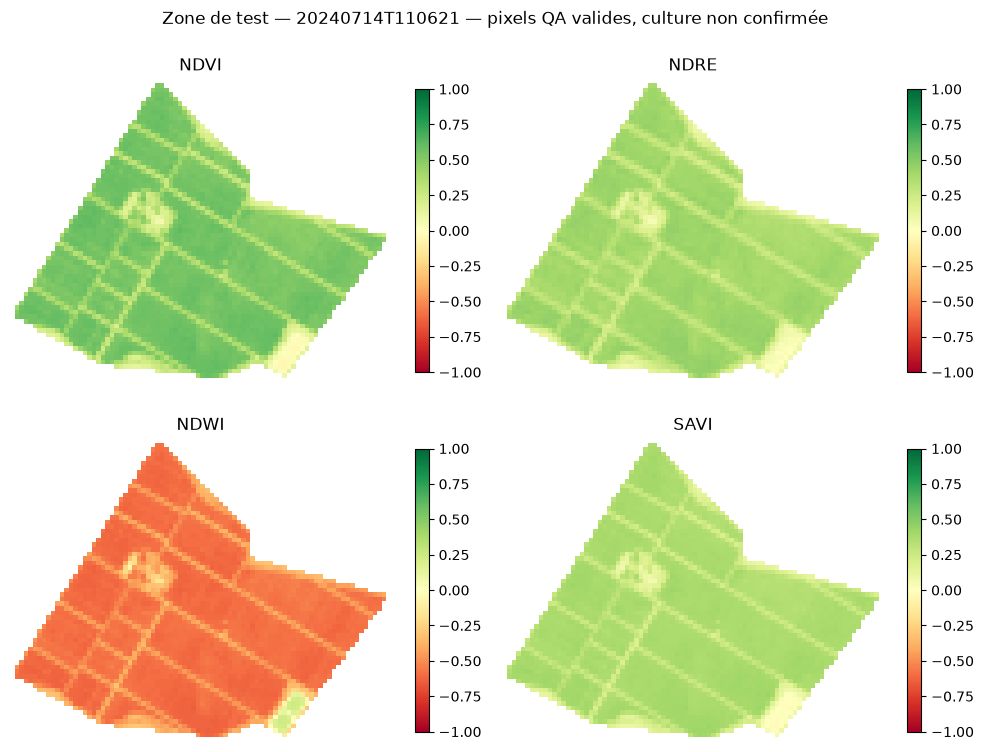

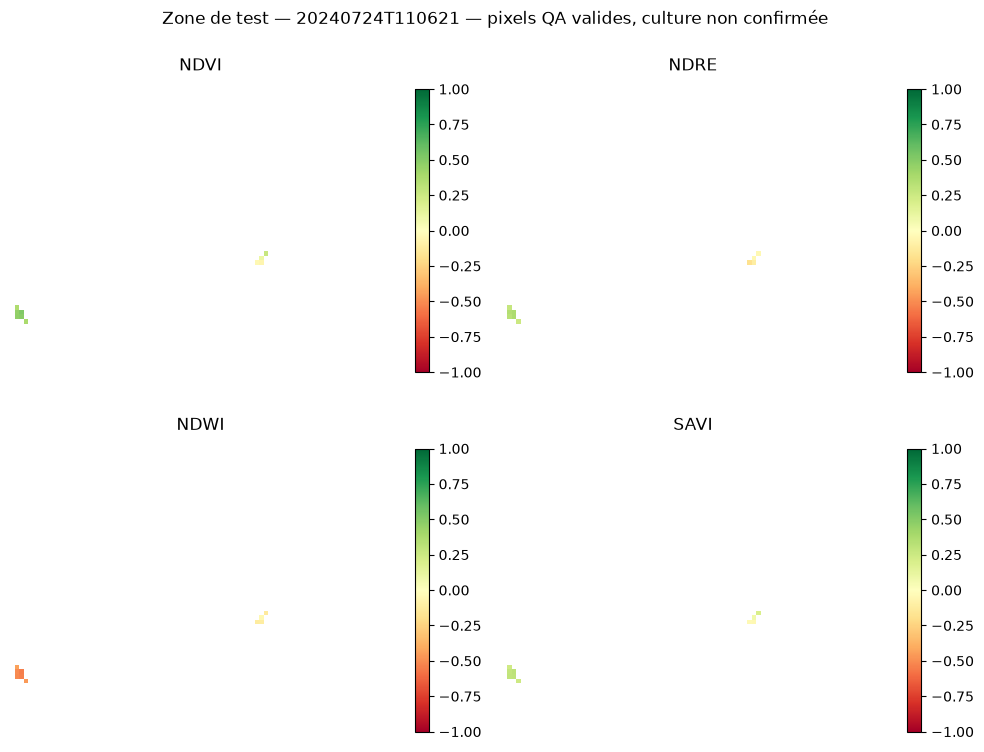

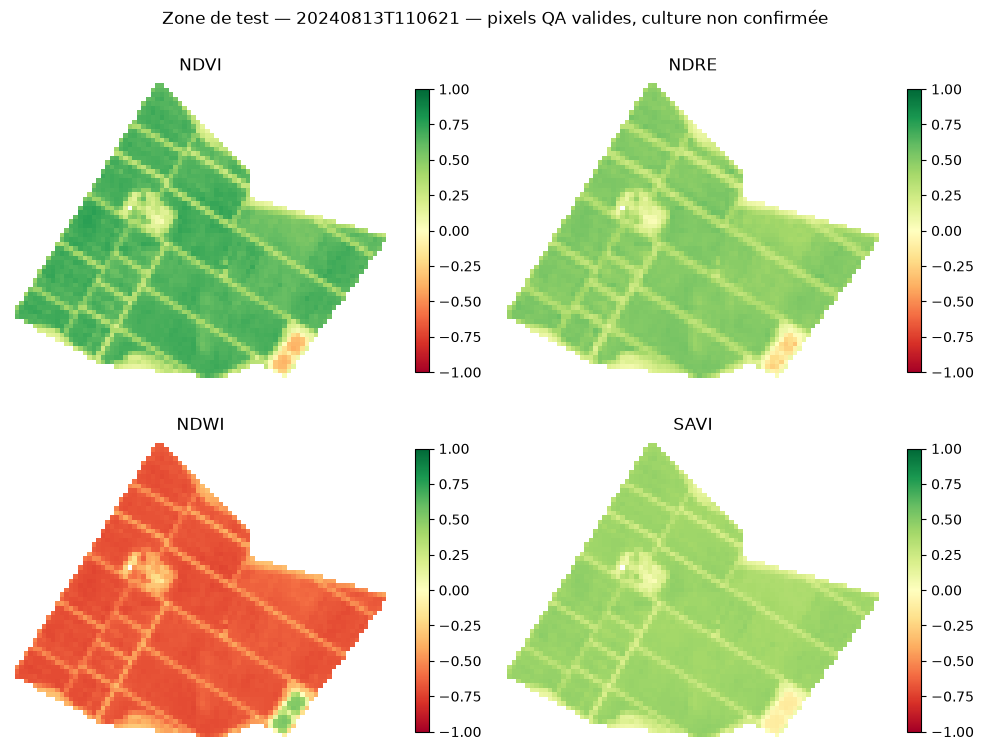

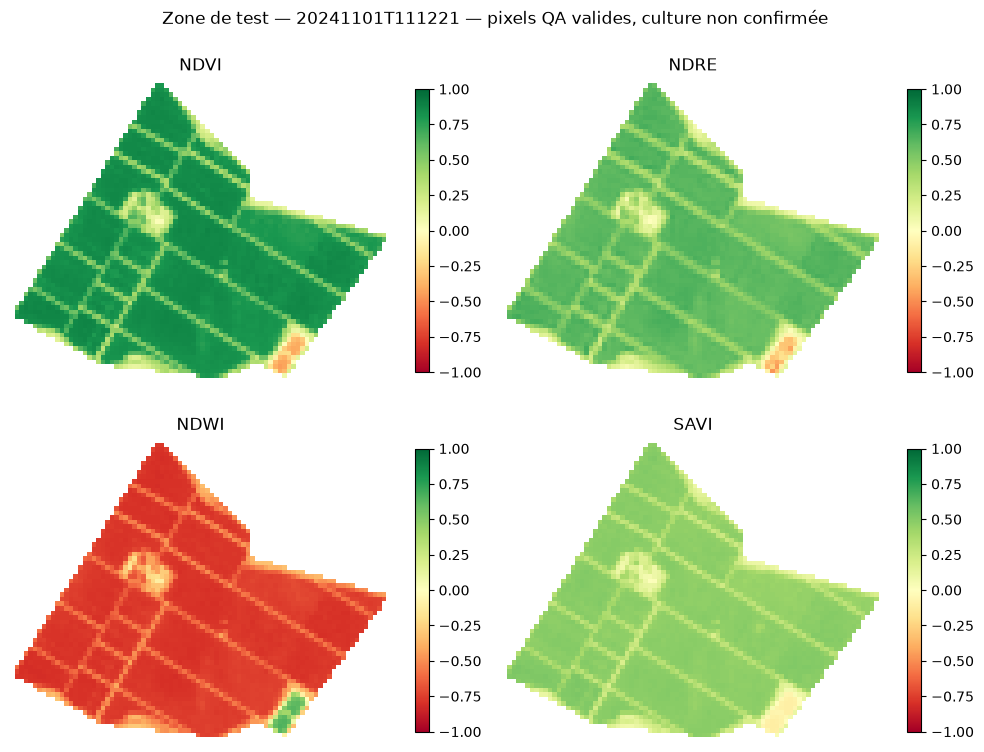

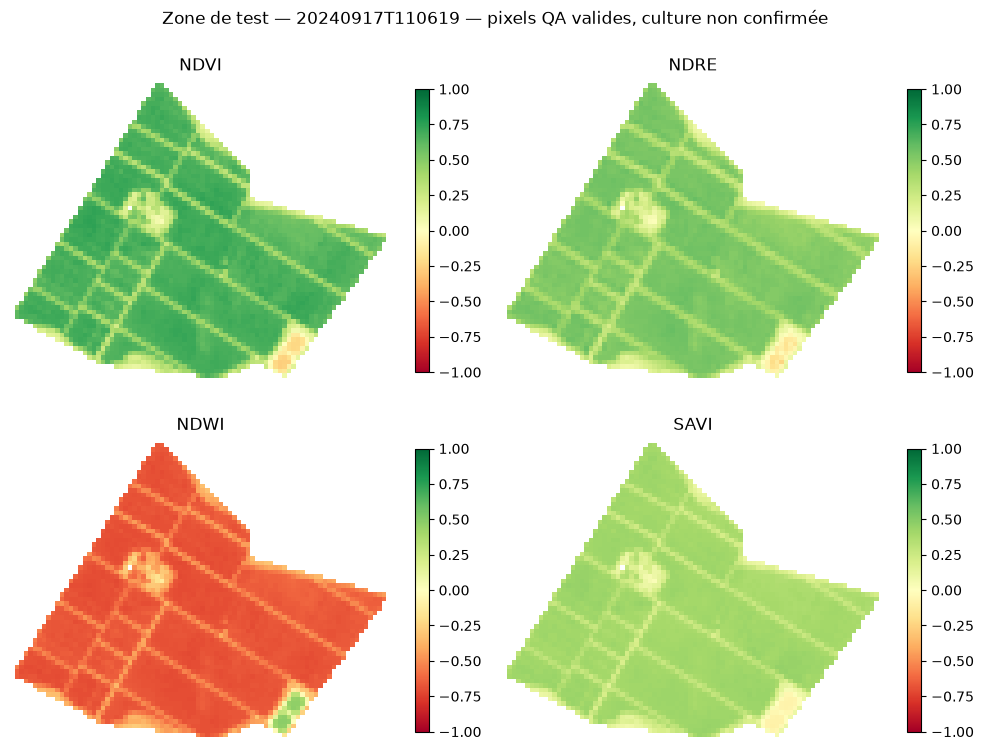

,zone_id,date,product,processing_baseline,n_zone_pixels,n_valid_pixels,valid_fraction,resolution_m,olive_presence_confirmed,usage,...,ndre_max,ndwi_mean,ndwi_median,ndwi_min,ndwi_max,savi_mean,savi_median,savi_min,savi_max,scl_counts
0,zone_test_001,2024-07-14T11:06:21.024Z,S2A_MSIL2A_20240714T110621_N0510_R137_T29SPR_2...,05.10,2923,2923,1.000000,20,False,test_technique,...,0.468031,-0.542499,-0.584705,-0.641175,0.235525,0.340081,0.372517,-0.018096,0.424559,"{""4"": 2107, ""5"": 816}"
1,zone_test_001,2024-07-24T11:06:21.024Z,S2A_MSIL2A_20240724T110621_N0511_R137_T29SPR_2...,05.11,2923,10,0.003421,20,False,test_technique,...,0.370960,-0.338970,-0.444606,-0.546330,-0.046628,0.186280,0.240788,-0.042909,0.309852,"{""3"": 2211, ""5"": 10, ""8"": 234, ""9"": 236, ""10"":..."
2,zone_test_001,2024-08-13T11:06:21.024Z,S2A_MSIL2A_20240813T110621_N0511_R137_T29SPR_2...,05.11,2923,2922,0.999658,20,False,test_technique,...,0.571327,-0.609109,-0.666330,-0.730172,0.535492,0.374485,0.414569,-0.133087,0.477835,"{""4"": 2300, ""5"": 622, ""7"": 1}"
3,zone_test_001,2024-11-01T11:12:21.024Z,S2A_MSIL2A_20241101T111221_N0511_R137_T29SPR_2...,05.11,2923,2923,1.000000,20,False,test_technique,...,0.692227,-0.695155,-0.761297,-0.811289,0.656336,0.422253,0.470510,-0.107120,0.534953,"{""4"": 2613, ""5"": 294, ""6"": 16}"
4,zone_test_001,2024-09-17T11:06:19.024Z,S2B_MSIL2A_20240917T110619_N0511_R137_T29SPR_2...,05.11,2923,2922,0.999658,20,False,test_technique,...,0.595578,-0.613797,-0.668987,-0.716085,0.482740,0.362607,0.400694,-0.086714,0.451029,"{""4"": 2333, ""5"": 589, ""7"": 1}"


Acquisitions distinctes : 5 ; aucun entraînement temporel lancé sur cette zone.


In [4]:
import zipfile
import xml.etree.ElementTree as ET
import rasterio
from rasterio.features import geometry_window, geometry_mask
from rasterio.warp import transform_geom
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling

def native_metadata(archive):
    xml=ET.fromstring(archive.read(next(n for n in archive.namelist() if n.endswith('/MTD_MSIL2A.xml'))))
    fields={}; offsets={}
    for node in xml.iter():
        tag=node.tag.split('}')[-1]
        if tag in ['PRODUCT_START_TIME','BOA_QUANTIFICATION_VALUE','PROCESSING_BASELINE']:
            fields[tag]=node.text
        if tag=='BOA_ADD_OFFSET': offsets[int(node.attrib['band_id'])]=float(node.text)
    # Les anciens produits sans offset explicite ont un offset nul.
    if float(fields['PROCESSING_BASELINE'])>=4 and not offsets:
        raise ValueError('Produit récent sans offsets XML : contrôle manuel requis')
    return fields,offsets

def local_indices(path, feature):
    geometry=feature['geometry']
    with zipfile.ZipFile(path) as archive:
        names=archive.namelist(); fields,offsets=native_metadata(archive)
        def member(band):
            resolution='10m' if band=='B08' else '20m'
            found=[n for n in names if n.endswith('_'+band+'_'+resolution+'.jp2')]
            if len(found)!=1: raise ValueError('Une seule granule attendue pour '+band)
            return '/vsizip/'+path.resolve().as_posix()+'/'+found[0]
        with rasterio.open(member('SCL')) as src:
            projected=transform_geom('EPSG:4326',src.crs,geometry)
            window=geometry_window(src,[projected])
            scl=src.read(1,window=window)
            affine=src.window_transform(window); crs=src.crs
            inside=geometry_mask([projected],out_shape=scl.shape,transform=affine,invert=True)
            full_transform=src.transform; full_shape=src.shape
        if inside.sum()==0: raise ValueError('Aucun centre de pixel dans la zone')
        valid=inside & np.isin(scl,[4,5,6])
        bands={}
        for band,band_id in [('B03',2),('B04',3),('B05',4),('B08',7),('B8A',8)]:
            with rasterio.open(member(band)) as src:
                if band=='B08':
                    with WarpedVRT(src,crs=crs,transform=full_transform,width=full_shape[1],height=full_shape[0],
                                   src_nodata=0,nodata=0,dtype='float32',resampling=Resampling.average) as aligned:
                        dn=aligned.read(1,window=window)
                else:
                    assert src.crs==crs and src.transform==full_transform and src.shape==full_shape, 'Grilles différentes'
                    dn=src.read(1,window=window)
                valid &= dn!=0
                bands[band]=(dn.astype(np.float32)+offsets.get(band_id,0))/float(fields['BOA_QUANTIFICATION_VALUE'])
        def ratio(a,b):
            den=a+b
            return np.divide(a-b,den,out=np.full_like(a,np.nan),where=np.abs(den)>1e-6)
        ndvi=ratio(bands['B08'],bands['B04'])
        ndre=ratio(bands['B8A'],bands['B05'])
        ndwi=ratio(bands['B03'],bands['B08'])
        den=bands['B08']+bands['B04']+.5
        savi=np.divide(1.5*(bands['B08']-bands['B04']),den,out=np.full_like(den,np.nan),where=np.abs(den)>1e-6)
        stack=np.stack([ndvi,ndre,ndwi,savi])
        valid &= np.isfinite(stack).all(axis=0)
        stack[:,~valid]=np.nan
        row=dict(zone_id=feature['properties']['zone_id'],date=fields['PRODUCT_START_TIME'],
                 product=path.name,processing_baseline=fields['PROCESSING_BASELINE'],
                 n_zone_pixels=int(inside.sum()),n_valid_pixels=int(valid.sum()),
                 valid_fraction=float(valid.sum()/inside.sum()),resolution_m=20,
                 olive_presence_confirmed=False,usage='test_technique')
        for band,array in zip(['ndvi','ndre','ndwi','savi'],stack):
            values=array[valid]
            for stat,fn in [('mean',np.mean),('median',np.median),('min',np.min),('max',np.max)]:
                row[band+'_'+stat]=float(fn(values)) if len(values) else None
        qa={str(int(k)):int(v) for k,v in zip(*np.unique(scl[inside],return_counts=True))}
        row['scl_counts']=json.dumps(qa)
        stamp=pd.Timestamp(fields['PRODUCT_START_TIME']).strftime('%Y%m%dT%H%M%S')
        dest=PROCESSED/('zone_test_'+stamp+'_indices.tif')
        with rasterio.open(dest,'w',driver='GTiff',height=stack.shape[1],width=stack.shape[2],
                           count=4,dtype='float32',crs=crs,transform=affine,nodata=np.nan,compress='deflate') as dst:
            dst.write(stack)
            for i,band in enumerate(['NDVI','NDRE','NDWI','SAVI'],1): dst.set_band_description(i,band)
        fig,axes=plt.subplots(2,2,figsize=(10,8))
        for ax,array,title in zip(axes.flat,stack,['NDVI','NDRE','NDWI','SAVI']):
            im=ax.imshow(array,cmap='RdYlGn',vmin=-1,vmax=1); ax.set_title(title); ax.axis('off')
            fig.colorbar(im,ax=ax,shrink=.75)
        fig.suptitle('Zone de test — '+stamp+' — pixels QA valides, culture non confirmée')
        fig.tight_layout(); fig.savefig(OUT/('zone_test_'+stamp+'_indices.png'),dpi=150)
        plt.show()
        return row

local_rows=[]
zone_path=morocco/'zone_test.geojson'
if zone_path.exists():
    collection=json.loads(zone_path.read_text(encoding='utf-8'))
    for path in sorted((RAW/'sentinel2').glob('*.zip')):
        for feature in collection['features']:
            local_rows.append(local_indices(path,feature))
    if local_rows:
        local_table=pd.DataFrame(local_rows)
        local_table.to_csv(PROCESSED/'local_zone_indices.csv',index=False)
        display(local_table)
        print('Acquisitions distinctes :',local_table.date.nunique(),'; aucun entraînement temporel lancé sur cette zone.')
else: print('Zone de test GeoJSON absente : traitement local non lancé.')

## Données importées sur des oliveraies documentées
Le bloc suivant expose l'intégralité du nouvel import public et de son audit.
Les traitements ne sont pas délégués à des scripts cachés. Le notebook d'import
autonome contient le même bloc pour faciliter le travail sur les données seules.
Les variables de chemins du protocole initial sont restaurées ensuite pour éviter
de mélanger les données du pilote avec celles de l'ancien essai.

In [5]:
_initial_paths = {key: globals()[key] for key in ['ROOT','RAW','META','PROCESSED','OUT','morocco']}

# OliveSmart - import de données sur des oliveraies documentées

Ce notebook contient le code intégral d'import et d'audit. Il complète le notebook
de comparaison existant, sans mélanger l'ancienne zone de culture non confirmée et
les nouvelles parcelles terrain. **Aucun modèle n'est entraîné ici.**

Référence terrain : Ouassanouan et al., *Crop and irrigation type dataset for Moroccan
agricultural regions*, [DOI version 2](https://doi.org/10.6084/m9.figshare.28486022.v2),
licence CC BY 4.0. Le champ `tree=Olives` constitue une observation publiée de culture,
pas un label de stress et pas une confirmation de la culture sur toutes les années.
La version a été publiée le 14 juillet 2025 : sélection rétrospective des sites.

Les capteurs restent ceux du sujet : Sentinel-2 L2A et Landsat Collection 2 L2.
Pour automatiser sans authentification Earth Engine, nous utilisons des miroirs COG
publics des mêmes produits : [Sentinel-2 C1 / Earth Search](https://registry.opendata.aws/sentinel-2-l2a-cogs/)
et Landsat / Planetary Computer. Ce ne sont pas des nouveaux jeux de données fusionnés.
L'accès météo est Open-Meteo avec le modèle explicitement fixé à ERA5-Land. Ce n'est
pas un export du catalogue Earth Engine DAILY_AGGR. Température et humidité du sol
seulement ; la pluie proposée par cette API est forcée par ERA5 et n'est pas substituée.


In [6]:
from pathlib import Path
from IPython.display import display, Image
import json
import pandas as pd
ROOT=Path.cwd()
assert (ROOT/'requirements.txt').exists(), 'Lancer le notebook dans SmartOlive_Sate'
RUN_DOWNLOAD=False  # True pour rechercher et importer ; reprise depuis les caches vérifiés.
RUN_REFERENCE_AUDIT=True
RUN_CONSOLIDATION=True
print('Répertoire :',ROOT.name)


Répertoire : SmartOlive_Sate


## 1. Archives originales et intégrité
Import des polygones et des bandes/NDVI publiés pour 2024 (~68 Mo), comparaison
au MD5 fournisseur, SHA-256 local et contrôle des noms avant extraction. Les photos
de 17 Go ne sont pas téléchargées ni présentées comme inspectées. Les CSV publiés
ne comportent pas de fractions de pixels QA ou de facteurs physiques explicites :
bandes conservées brutes, NDVI fourni conservé sans recalcul d'autres indices.


In [7]:
if RUN_DOWNLOAD:
    """Import reproductible de la référence terrain publiée (culture, pas stress)."""
    from pathlib import Path
    import hashlib
    import json
    import requests
    import subprocess
    import socket
    import urllib3.util.connection
    from requests.adapters import HTTPAdapter
    from urllib3.util.retry import Retry
    from datetime import datetime, timezone
    
    ROOT=Path.cwd()
    RAW=ROOT/'data/raw/morocco_reference'; RAW.mkdir(parents=True,exist_ok=True)
    META=ROOT/'data/metadata'; META.mkdir(parents=True,exist_ok=True)
    URL='https://api.figshare.com/v2/articles/28486022/versions/2'
    urllib3.util.connection.allowed_gai_family=lambda: socket.AF_INET
    session=requests.Session()
    session.mount('https://',HTTPAdapter(max_retries=Retry(total=3,backoff_factor=1,status_forcelist=[429,500,502,503,504])))
    response=session.get(URL,timeout=60); response.raise_for_status(); article=response.json()
    (META/'morocco_reference_figshare_v2.json').write_text(json.dumps(article,indent=2),encoding='utf-8')
    manifest=[]
    for f in sorted(article['files'],key=lambda f:f['size']):
        if f['size']>100_000_000: continue  # Photos 17 Go : pas nécessaires à cet import des polygones.
        target=RAW/('parcels.rar' if f['id']==56267117 else 'sentinel2_2024.rar')
        part=target.with_suffix('.part')
        if not target.exists():
            offset=part.stat().st_size if part.exists() else 0
            download_url=f"https://api.figshare.com/v2/file/download/{f['id']}"
            with session.get(download_url,stream=True,headers={'Range':f'bytes={offset}-'} if offset else {},timeout=(15,90)) as r:
                r.raise_for_status()
                mode='ab' if offset and r.status_code==206 else 'wb'
                with part.open(mode) as stream:
                    for block in r.iter_content(1024*1024): stream.write(block)
            assert part.stat().st_size==f['size'],'Taille incorrecte'
            part.replace(target)
        assert target.stat().st_size==f['size']
        md5=hashlib.md5(target.read_bytes()).hexdigest()
        assert md5==f['computed_md5'],'MD5 fournisseur incorrect'
        print(target.name,target.stat().st_size,'MD5 fournisseur OK',flush=True)
        manifest.append(dict(source=article['doi'],version=2,url=f['download_url'],original_name=f['name'],file=str(target.relative_to(ROOT)),bytes=target.stat().st_size,md5=md5,sha256=hashlib.sha256(target.read_bytes()).hexdigest(),license=article['license'],integrity='Taille et MD5 fournisseur vérifiés',retrieved_utc=datetime.now(timezone.utc).isoformat()))
        listing=subprocess.run(['tar','-tf',str(target)],capture_output=True,text=True,check=True)
        print(listing.stdout[:2500],flush=True)
        # Contrôle des noms avant extraction, aucune traversée hors destination.
        for name in listing.stdout.splitlines():
            dest=(RAW/name).resolve()
            assert dest.is_relative_to(RAW.resolve()),'Chemin archive non sûr'
        subprocess.run(['tar','-xf',str(target),'-C',str(RAW)],check=True)
    (META/'morocco_reference_manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
    print('Import référence terminé',flush=True)


## 2. Audit des cultures et sélection du pilote
Inventaire complet des lignes `tree=Olives`. La géométrie invalide est conservée dans
l'inventaire et exclue du pilote. Les cultures intercalaires sont distinguées.
Les doublons identiques sont dédupliqués ; toutes les lignes de dates contradictoires
sans identifiant de scène sont exclues du tableau dérivé et consignées. Aucun original
n'est modifié. Les séries absentes restent absentes.

Pilote : trois parcelles à El Haouz et trois au Tadla, choisies sans voir les résultats
satellites parmi les oliveraies sans culture intercalaire indiquée, valides et d'au moins
un hectare. Leur voisinage facilite les découpes. Le plus grand champ de chaque région
sert d'ancre. Aucun identifiant de ferme ou de bassin n'est fabriqué : ces valeurs restent
nulles. Les régions du fournisseur ne sont pas des bassins hydrologiques.


In [8]:
if RUN_REFERENCE_AUDIT:
    """Audit du terrain publié et sélection d'un petit pilote sans étiquettes inventées."""
    from pathlib import Path
    import json
    import geopandas as gpd
    import pandas as pd
    from shapely.geometry import box
    
    ROOT=Path.cwd()
    RAW=ROOT/'data/raw/morocco_reference'
    META=ROOT/'data/metadata'; OUT=ROOT/'data/processed'; OUT.mkdir(exist_ok=True)
    fields=gpd.read_file(next(RAW.rglob('*.shp')))
    assert fields.crs.to_epsg()==4326
    assert fields.parcel_id.is_unique
    olive=fields[fields.tree.eq('Olives')].copy()
    olive['area_ha']=olive.to_crs(6933).area/10000
    olive['geometry_valid']=olive.geometry.is_valid
    olive['crop_observed_at']=pd.to_datetime(olive.date).dt.strftime('%Y-%m-%d')
    olive['crop_evidence']='terrain publié : tree=Olives ; DOI 10.6084/m9.figshare.28486022.v2'
    olive['stress_label']=None
    olive['farm_id']=None
    olive['basin_id']=None
    olive['source_doi']='10.6084/m9.figshare.28486022.v2'
    olive['source_release_date']='2025-07-14'
    olive['mixed_crop']=~olive.crop.eq('Trees')
    olive['date']=olive.crop_observed_at
    dest=ROOT/'data/raw/maroc/oliveraies_reference.geojson'
    olive.to_file(dest,driver='GeoJSON')
    olive.drop(columns='geometry').to_csv(OUT/'olive_parcels_inventory.csv',index=False)
    files={p.stem.removesuffix('_S2_timeseries'):p for p in RAW.rglob('*_S2_timeseries.csv') if '.ipynb_checkpoints' not in p.parts}
    records=[]; missing=[]; duplicate_audit=[]
    for row in olive.itertuples():
        path=files.get(row.parcel_id)
        if path is None: missing.append(row.parcel_id); continue
        df=pd.read_csv(path)
        assert {'NDVI','date'}<=set(df),str(path)
        df['date']=pd.to_datetime(df.date,errors='raise')
        n_exact=int(df.duplicated().sum())
        df=df.drop_duplicates().copy()
        conflicting=df.date.duplicated(keep=False)
        if n_exact or conflicting.any():
            duplicate_audit.append(dict(parcel_id=row.parcel_id,exact_duplicates_removed=n_exact,
                                        ambiguous_rows_excluded=int(conflicting.sum())))
        # Sans identifiant d'acquisition, ne pas choisir arbitrairement entre deux valeurs.
        df=df.loc[~conflicting].copy()
        df['parcel_id']=row.parcel_id
        df['region']=row.zone
        df['source_file']=str(path.relative_to(ROOT))
        df['qa_coverage_available']=False
        df['stress_label']=None
        records.append(df)
    series=pd.concat(records,ignore_index=True).sort_values(['parcel_id','date'])
    series.to_csv(OUT/'olive_reference_series_2024.csv',index=False)
    pd.DataFrame(duplicate_audit).to_csv(META/'reference_series_duplicate_audit.csv',index=False)
    eligible=olive[olive.geometry_valid & olive.crop.eq('Trees') & olive.area_ha.ge(1)].copy()
    # Deux régions publiées ; choisir les parcelles les plus proches de la plus grande
    # de chaque région. Aucun résultat satellite ne participe à cette sélection.
    pilots=[]
    for region in ['el haouz','Tadla']:
        candidates=eligible[eligible.zone.eq(region)].copy()
        projected=candidates.to_crs(32629)
        anchor=projected.loc[candidates.area_ha.idxmax()].geometry.centroid
        candidates['distance_to_anchor_m']=projected.geometry.centroid.distance(anchor)
        pilots.append(candidates.sort_values(['distance_to_anchor_m','parcel_id']).head(3))
    pilot=gpd.GeoDataFrame(pd.concat(pilots,ignore_index=True),crs=4326)
    pilot.to_file(ROOT/'data/raw/maroc/oliveraies_pilote.geojson',driver='GeoJSON')
    pilot.drop(columns='geometry').to_csv(OUT/'olive_pilot_inventory.csv',index=False)
    summary=dict(source_doi='10.6084/m9.figshare.28486022.v2',license='CC BY 4.0',
                 all_parcels=len(fields),olive_labelled_parcels=len(olive),
                 pure_olive_parcels=int(olive.crop.eq('Trees').sum()),invalid_olive_geometries=int((~olive.geometry_valid).sum()),
                 parcels_with_published_series=int(series.parcel_id.nunique()),series_rows=len(series),
                 first_date=str(series.date.min()),last_date=str(series.date.max()),
                 missing_series=missing,regions=olive.zone.value_counts().to_dict(),
                 exact_duplicate_rows_removed=sum(r['exact_duplicates_removed'] for r in duplicate_audit),
                 ambiguous_rows_excluded=sum(r['ambiguous_rows_excluded'] for r in duplicate_audit),
                 pilot_parcels=pilot.parcel_id.tolist(),
                 caveats=['Culture observée au jour de visite, pas confirmation rétroactive sur toutes les années.',
                          'Aucun label de stress ; aucun identifiant exploitation ou bassin hydrologique fourni.',
                          'Bandes des CSV publiés conservées brutes : facteur/offset et taux de pixels QA non fournis dans les fichiers.',
                          'NDVI fourni par les auteurs conservé sans recalcul ; indices physiques à extraire des rasters audités.',
                          'Les régions source ne sont pas des bassins hydrologiques.',
                          'La géométrie invalide reste dans inventaire et est exclue du pilote sans correction silencieuse.'])
    (META/'morocco_reference_audit.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False),encoding='utf-8')
    print(json.dumps(summary,indent=2,ensure_ascii=False))
    print(pilot[['parcel_id','zone','area_ha','distance_to_anchor_m']].to_string(index=False))
    print('BBox pilote :',pilot.total_bounds)


{
  "source_doi": "10.6084/m9.figshare.28486022.v2",
  "license": "CC BY 4.0",
  "all_parcels": 10383,
  "olive_labelled_parcels": 868,
  "pure_olive_parcels": 564,
  "invalid_olive_geometries": 1,
  "parcels_with_published_series": 855,
  "series_rows": 29886,
  "first_date": "2024-01-01 00:00:00",
  "last_date": "2024-12-26 00:00:00",
  "missing_series": [
    "Tadla_Trees_20240222_019",
    "Tadla_mixte_20240223_003",
    "Tadla_mixte_20240223_004",
    "Tadla_mixte_20240223_005",
    "Tadla_mixte_20240223_006",
    "Tadla_mixte_20240223_007",
    "Tadla_Trees_20240223_003",
    "Tadla_mixte_20240223_008",
    "Tadla_mixte_20240223_009",
    "Tadla_mixte_20240223_010",
    "Tadla_mixte_20240223_011",
    "Tadla_mixte_20240223_012",
    "Tadla_mixte_20240223_013"
  ],
  "regions": {
    "el haouz": 647,
    "Tadla": 185,
    "Doukkala": 15,
    "Gharb": 9,
    "Souss": 7,
    "Statte": 5
  },
  "exact_duplicate_rows_removed": 1,
  "ambiguous_rows_excluded": 16609,
  "pilot_parcels": 

## 3. Séries satellitaires sur les mêmes polygones
Sentinel-2 C1 2021-2024 : un candidat par fenêtre de 10 jours. Landsat 8/9 Collection 2
2015-2024 : un candidat par mois pour un historique indépendant. Sélection par nuages
de scène avant calcul des indices ; couverture de l'ensemble du groupe vérifiée.
**Échantillonnage, pas composite de toutes les acquisitions.** Les fenêtres sans candidat
ou de mauvaise qualité restent des trous. Une autre scène peut être utile si le meilleur
candidat de scène est localement nuageux : cette reprise locale n'est pas encore implémentée.

Les fenêtres COG sont lues et conservées en NPZ avec grille, SHA-256 et URLs sources
non signées. Les offsets/échelles des assets C1 sont appliqués ; l'ancien miroir S2
aux offsets contradictoires a été exclu. Grille commune à 20 m, moyennes pour bandes
spectrales et plus proche voisin pour QA. SCL 4/5 conservées ; eau et nuages exclus.
Landsat : QA_PIXEL (bits 0-5) et saturation B4/B5/occlusion terrain (QA_RADSAT).
NDVI, NDRE, NDWI vert/NIR et SAVI L=0,5 pour S2 ; NDVI séparé pour Landsat.


In [9]:
"""Import public de découpes Sentinel-2/Landsat sur six parcelles terrain.

Les COG sont des miroirs des produits ESA/USGS, pas de nouveaux capteurs.
Un candidat au maximum par fenêtre de 10 jours (S2) ou mois (Landsat), choisi
sur nuages de scène ; les trous et rejets locaux restent explicites.
"""
from pathlib import Path
import argparse
import concurrent.futures
import hashlib
import json
import math
import time
import threading
from urllib.parse import urlparse
from datetime import datetime, timezone
import geopandas as gpd
import numpy as np
import pandas as pd
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
import rasterio
from rasterio.features import geometry_mask
from rasterio.transform import from_origin
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
from shapely.geometry import shape

ROOT=Path.cwd()
RAW=ROOT/'data/raw/pilot'; META=ROOT/'data/metadata/pilot'; OUT=ROOT/'data/processed/pilot'
for p in [RAW,META,OUT]:p.mkdir(parents=True,exist_ok=True)
PILOT=gpd.read_file(ROOT/'data/raw/maroc/oliveraies_pilote.geojson')
CONFIG={'processing_version':2,'sentinel_start':'2021-01-01','landsat_start':'2015-01-01','end':'2024-12-31',
        'step_days':10,'max_scene_cloud':40,'min_valid_fraction':.6,
        'selection':'minimum eo:cloud_cover parmi les scènes couvrant le groupe, par fenêtre, sans accès aux résultats',
        'qa_sentinel_classes':[4,5], 'note':'eau exclue du pilote oléicole ; échantillonnage temporel, pas composite de toutes les scènes'}
SAS_CACHE={}
SAS_LOCK=threading.Lock()
from types import SimpleNamespace
args=SimpleNamespace(smoke=False, source="all", workers=4)
def session():
    s=requests.Session(); s.mount('https://',HTTPAdapter(max_retries=Retry(total=2,backoff_factor=1,status_forcelist=[429,500,502,503,504])))
    return s

def search(region,group,source):
    start='2024-06-01' if args.smoke else CONFIG['sentinel_start' if source=='sentinel2' else 'landsat_start']
    end='2024-06-30' if args.smoke else CONFIG['end']
    col='sentinel-2-c1-l2a' if source=='sentinel2' else 'landsat-c2-l2'
    api='https://earth-search.aws.element84.com/v1/search' if source=='sentinel2' else 'https://planetarycomputer.microsoft.com/api/stac/v1/search'
    slug=region.replace(' ','_')
    dest=META/f'{col}_{slug}_{start}_{end}_catalogue.json'
    if dest.exists(): items=json.loads(dest.read_text())['features']
    else:
        items=[]; client=session()
        for year in range(int(start[:4]),int(end[:4])+1):
            begin=max(start,f'{year}-01-01');finish=min(end,f'{year}-12-31')
            yearfile=META/f'{col}_{slug}_{begin}_{finish}_part.json'
            if yearfile.exists():items.extend(json.loads(yearfile.read_text())['features']);continue
            yearitems=[];url=api
            params={'collections':col,'bbox':','.join(map(str,group.total_bounds)),
                    'datetime':begin+'T00:00:00Z/'+finish+'T23:59:59Z','limit':100}
            while url:
                r=client.get(url,params=params,timeout=(20,90));r.raise_for_status();data=r.json()
                yearitems.extend(data['features'])
                link=next((l for l in data.get('links',[]) if l['rel']=='next'),None)
                url=link['href'] if link else None;params=None
            yearfile.write_text(json.dumps({'type':'FeatureCollection','features':yearitems}))
            items.extend(yearitems)
        dest.write_text(json.dumps({'type':'FeatureCollection','features':items},indent=2))
    union=group.geometry.union_all()
    candidates={}
    for item in items:
        props=item['properties']; cloud=props.get('eo:cloud_cover',100)
        if cloud is None or cloud>CONFIG['max_scene_cloud']:continue
        if not shape(item['geometry']).covers(union):continue
        if source=='landsat' and props.get('platform') not in ['landsat-8','landsat-9']:continue
        dt=pd.Timestamp(props['datetime'])
        # Origine annuelle fixe, la dernière fenêtre de l'année peut être courte.
        key=(dt.year,(dt.dayofyear-1)//10) if source=='sentinel2' else (dt.year,dt.month)
        rank=(cloud,props['datetime'],item['id'])
        if key not in candidates or rank<candidates[key][0]:candidates[key]=(rank,item)
    selected=[v[1] for _,v in sorted(candidates.items())]
    if args.smoke:selected=selected[:1]
    print(source,region,':',len(items),'catalogue,',len(selected),'candidats retenus',flush=True)
    return selected

def raster_crop(item,key,source,grid,client):
    asset=item['assets'][key]; url=asset['href']
    if source=='landsat':
        parsed=urlparse(url)
        account=parsed.hostname.split('.')[0];container=parsed.path.split('/')[1]
        cache_key=(account,container)
        with SAS_LOCK:
            if cache_key not in SAS_CACHE:
                sign=client.get(f'https://planetarycomputer.microsoft.com/api/sas/v1/token/{account}/{container}',timeout=30)
                sign.raise_for_status();SAS_CACHE[cache_key]=sign.json()['token']
            token=SAS_CACHE[cache_key]
        url=url+'?'+token
    qa=key in ['scl','qa_pixel','qa_radsat']
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN='EMPTY_DIR',CPL_VSIL_CURL_ALLOWED_EXTENSIONS='.tif,.TIF',
                      GDAL_HTTP_CONNECTTIMEOUT=20,GDAL_HTTP_TIMEOUT=60,GDAL_HTTP_MAX_RETRY=2,GDAL_HTTP_RETRY_DELAY=1,
                      GDAL_HTTP_IPRESOLVE='V4',VSI_CACHE=True):
        with rasterio.open(url) as src:
            with WarpedVRT(src,crs='EPSG:32629',transform=grid['transform'],width=grid['width'],height=grid['height'],
                           src_nodata=src.nodata,nodata=0,resampling=Resampling.nearest if qa else Resampling.average,
                           dtype='uint16' if qa else 'float32') as warped:
                array=warped.read(1)
    metadata=asset.get('raster:bands',[{}])[0]
    if not qa:
        if 'scale' not in metadata:raise ValueError('Facteur physique manquant dans STAC : '+item['id']+' '+key)
        valid=array!=metadata.get('nodata',0)
        array=array*metadata['scale']+metadata.get('offset',0)
        array[~valid]=np.nan
    return array

def process(region,group,source,item):
    slug=region.replace(' ','_'); folder=RAW/source/slug;folder.mkdir(parents=True,exist_ok=True)
    dest=folder/(item['id']+'.npz'); stats=folder/(item['id']+'.json')
    if dest.exists() and stats.exists():
        prior=json.loads(stats.read_text())
        if prior.get('config',{}).get('processing_version')==CONFIG['processing_version'] and hashlib.sha256(dest.read_bytes()).hexdigest()==prior['sha256']:return prior['rows']
    projected=group.to_crs(32629)
    resolution=20 if source=='sentinel2' else 30
    xmin,ymin,xmax,ymax=projected.total_bounds
    xmin=math.floor(xmin/resolution)*resolution;ymax=math.ceil(ymax/resolution)*resolution
    grid=dict(transform=from_origin(xmin,ymax,resolution,resolution),width=math.ceil((xmax-xmin)/resolution),height=math.ceil((ymax-ymin)/resolution))
    client=session()
    keys=['scl','green','red','rededge1','nir','nir08'] if source=='sentinel2' else ['qa_pixel','qa_radsat','red','nir08']
    arrays={key:raster_crop(item,key,source,grid,client) for key in keys}
    if source=='sentinel2':valid=np.isin(arrays['scl'],CONFIG['qa_sentinel_classes'])
    else:
        valid=(arrays['qa_pixel'] & 63)==0
        # L8/L9 : saturation des seules bandes utilisées B4/B5 + occlusion terrain.
        valid &= (arrays['qa_radsat'] & ((1<<3)|(1<<4)|(1<<11)))==0
    for key in keys:
        if key not in ['scl','qa_pixel','qa_radsat']:valid &= np.isfinite(arrays[key])
    def ratio(a,b):
        den=a+b
        return np.divide(a-b,den,out=np.full_like(den,np.nan),where=np.abs(den)>1e-6)
    nir=arrays['nir'] if source=='sentinel2' else arrays['nir08'];red=arrays['red']
    indices={'ndvi':ratio(nir,red)}
    if source=='sentinel2':
        indices['ndre']=ratio(arrays['nir08'],arrays['rededge1'])
        indices['ndwi']=ratio(arrays['green'],nir)
        den=nir+red+.5
        indices['savi']=np.divide(1.5*(nir-red),den,out=np.full_like(den,np.nan),where=np.abs(den)>1e-6)
    for values in indices.values():valid &= np.isfinite(values)
    rows=[]
    for row in projected.itertuples():
        inside=geometry_mask([row.geometry.__geo_interface__],out_shape=valid.shape,transform=grid['transform'],invert=True)
        good=inside & valid;n=int(inside.sum());ng=int(good.sum())
        fraction=ng/n if n else 0
        result=dict(parcel_id=row.parcel_id,region=region,date=item['properties']['datetime'],source=source,
                    item_id=item['id'],scene_cloud_percent=item['properties'].get('eo:cloud_cover'),
                    n_pixels=n,n_valid_pixels=ng,valid_fraction=fraction,accepted=fraction>=CONFIG['min_valid_fraction'],
                    crop_observed_at=str(row.crop_observed_at)[:10],source_release_date='2025-07-14',stress_label=None)
        for name,array in indices.items():
            result[name]=float(np.mean(array[good])) if ng else None
        rows.append(result)
    temp=dest.with_suffix('.part.npz')
    np.savez_compressed(temp,**arrays,valid_mask=valid,transform=np.array(tuple(grid['transform'])),crs='EPSG:32629')
    temp.replace(dest)
    metadata={'item_id':item['id'],'source':source,'date':item['properties']['datetime'],
              'unsigned_assets':{k:item['assets'][k] for k in keys},'config':CONFIG,
              'file':str(dest.relative_to(ROOT)),'sha256':hashlib.sha256(dest.read_bytes()).hexdigest(),
              'grid':{'crs':'EPSG:32629','transform':list(grid['transform']),'width':grid['width'],'height':grid['height']},
              'scale_policy':'raster:bands scale et offset appliqués ; aucun offset supplémentaire fondé sur le nom',
              'rows':rows,'retrieved_utc':datetime.now(timezone.utc).isoformat()}
    stats.write_text(json.dumps(metadata,indent=2,ensure_ascii=False))
    print(source,region,item['id'],'OK',flush=True)
    return rows

def main():
    (META/'import_config.json').write_text(json.dumps(CONFIG,indent=2))
    tasks=[]
    for region,group in PILOT.groupby('zone'):
        for source in (['sentinel2','landsat'] if args.source=='all' else [args.source]):
            for item in search(region,group,source):tasks.append((region,group,source,item))
    errors=[];rows=[]
    with concurrent.futures.ThreadPoolExecutor(max_workers=args.workers) as pool:
        futures={pool.submit(process,*task):task for task in tasks}
        for future in concurrent.futures.as_completed(futures):
            task=futures[future]
            try:rows.extend(future.result())
            except Exception as exc:
                if isinstance(exc,TypeError):
                    import traceback
                    traceback.print_exc(limit=8)
                # Ne pas stocker de lien SAS dans le diagnostic.
                error=dict(source=task[2],region=task[0],item_id=task[3]['id'],error_type=type(exc).__name__)
                errors.append(error);print('ERREUR',error,flush=True)
    suffix='_smoke' if args.smoke else ''
    pd.DataFrame(rows).to_csv(OUT/f'satellite_acquisitions{suffix}_{args.source}.csv',index=False)
    (META/f'import_errors{suffix}_{args.source}.json').write_text(json.dumps(errors,indent=2))
    print('Terminé :',len(rows),'observations parcelle-date ;',len(errors),'erreurs',flush=True)
    if errors:raise SystemExit(2)
if RUN_DOWNLOAD:
    main()


## 4. Météo ERA5-Land, point de grille régional
Les deux points sont les centroïdes des ensembles de parcelles projetés en UTM,
reconvertis en WGS84. Les coordonnées du point de grille effectivement retourné sont
conservées. Modèle `era5_land`, UTC, altitude non corrigée, maille la plus proche.
Variables : température moyenne (°C) et humidité volumique du sol 0-7 cm (m³/m³),
du 1er janvier 2021 au 31 décembre 2024. Pas de mesure locale d'irrigation.
[Documentation des modèles et variables](https://open-meteo.com/en/docs/historical-weather-api).


In [10]:
if RUN_DOWNLOAD:
    """ERA5-Land via Open-Meteo, modèle explicitement fixé, sans mélange de pluie ERA5."""
    from pathlib import Path
    import json
    import hashlib
    from datetime import datetime,timezone
    import requests
    import geopandas as gpd
    import pandas as pd
    
    ROOT=Path.cwd()
    RAW=ROOT/'data/raw/pilot/era5_land_openmeteo';RAW.mkdir(parents=True,exist_ok=True)
    META=ROOT/'data/metadata/pilot';META.mkdir(parents=True,exist_ok=True)
    OUT=ROOT/'data/processed/pilot';OUT.mkdir(parents=True,exist_ok=True)
    pilot=gpd.read_file(ROOT/'data/raw/maroc/oliveraies_pilote.geojson')
    records=[];manifest=[]
    for region,group in pilot.groupby('zone'):
        center=group.to_crs(32629).geometry.union_all().centroid
        point=gpd.GeoSeries([center],crs=32629).to_crs(4326).iloc[0]
        path=RAW/(region.replace(' ','_')+'_2021_2024.json')
        params=dict(latitude=point.y,longitude=point.x,start_date='2021-01-01',end_date='2024-12-31',
                    models='era5_land',daily='temperature_2m_mean,soil_moisture_0_to_7cm_mean',
                    timezone='UTC',elevation='nan',cell_selection='nearest')
        if path.exists():data=json.loads(path.read_text())
        else:
            response=requests.get('https://archive-api.open-meteo.com/v1/archive',params=params,timeout=(20,120))
            if response.status_code!=200:raise ValueError(response.text[:300])
            data=response.json();path.write_text(json.dumps(data,indent=2))
        assert data['daily_units']['temperature_2m_mean']=='°C'
        assert data['daily_units']['soil_moisture_0_to_7cm_mean']=='m³/m³'
        frame=pd.DataFrame(data['daily']).rename(columns={'time':'date','temperature_2m_mean':'temperature_c','soil_moisture_0_to_7cm_mean':'soil_moisture_m3m3'})
        frame['date']=pd.to_datetime(frame.date)
        assert len(frame)==1461 and frame.date.is_unique
        assert frame.temperature_c.notna().all() and frame.soil_moisture_m3m3.notna().all()
        frame['weather_region']=region;frame['model']='ERA5-Land';frame['access_provider']='Open-Meteo'
        frame['grid_latitude']=data['latitude'];frame['grid_longitude']=data['longitude']
        records.append(frame)
        manifest.append(dict(file=str(path.relative_to(ROOT)),bytes=path.stat().st_size,
                             sha256=hashlib.sha256(path.read_bytes()).hexdigest(),published_checksum=None,
                             source='Copernicus ERA5-Land, accès et agrégations Open-Meteo',
                             url='https://archive-api.open-meteo.com/v1/archive',request=params,
                             response_units=data['daily_units'],response_grid={'latitude':data['latitude'],'longitude':data['longitude']},
                             integrity='JSON, unités, calendrier complet et valeurs non nulles vérifiés',
                             retrieved_utc=datetime.now(timezone.utc).isoformat(),
                             caveat='Point de grille régional, non une station dans la parcelle. Pas le produit Earth Engine DAILY_AGGR ; pas de pluie ERA5 ajoutée silencieusement.'))
        print(region,len(frame),'jours ERA5-Land importés',flush=True)
    pd.concat(records,ignore_index=True).to_csv(OUT/'era5_land_daily_2021_2024.csv',index=False)
    (META/'weather_manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')


## 5. Consolidation, contrôles et résultats
Seules les découpes de version de traitement valide et SHA-256 vérifié entrent dans
le tableau final. Les autres essais restent dans les fichiers bruts mais sont exclus.
La date de chaque fenêtre est sa fin exclusive ; l'acquisition et les jours météo
précèdent cette date. Pas d'interpolation, pas de remplissage depuis le futur.
La météo n'est agrégée que si tous les jours sont disponibles. Les valeurs d'indices
ne sont exposées à l'apprentissage que si fraction QA ≥0,6 et plages admissibles.
Les observations rejetées sont conservées dans le journal d'acquisitions.


In [11]:
if RUN_CONSOLIDATION:
    """Consolide uniquement les découpes vérifiées, conserve les trous et la provenance."""
    from pathlib import Path
    import hashlib
    import json
    from datetime import timedelta
    import geopandas as gpd
    import pandas as pd
    import numpy as np
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    
    ROOT=Path.cwd()
    RAW=ROOT/'data/raw/pilot'; META=ROOT/'data/metadata/pilot';OUT=ROOT/'data/processed/pilot'
    REPORT=ROOT/'outputs/pilot';REPORT.mkdir(parents=True,exist_ok=True)
    pilot=gpd.read_file(ROOT/'data/raw/maroc/oliveraies_pilote.geojson')
    rows=[];manifest=[]
    full_run=OUT/'satellite_acquisitions_all.csv'
    assert full_run.exists(),'Attendre la fin du téléchargement complet avant consolidation'
    selected=pd.read_csv(full_run)
    selected_ids=set(zip(selected.source,selected.item_id))
    for source in ['sentinel2','landsat']:
        for path in (RAW/source).rglob('*.json'):
            data=json.loads(path.read_text())
            if data.get('config',{}).get('processing_version')!=2:continue
            if (source,data['item_id']) not in selected_ids:continue
            # Exclure tous les essais de l'ancien miroir aux offsets contradictoires.
            if source=='sentinel2' and not data['item_id'].startswith(('S2A_T','S2B_T','S2C_T')):continue
            target=ROOT/data['file']
            assert hashlib.sha256(target.read_bytes()).hexdigest()==data['sha256']
            rows.extend(data['rows'])
            manifest.append({k:data[k] for k in ['source','item_id','date','file','sha256','retrieved_utc']})
    frame=pd.DataFrame(rows)
    assert len(frame),'Aucune découpe vérifiée'
    frame['date']=pd.to_datetime(frame.date,utc=True)
    assert not frame.duplicated(['parcel_id','source','date']).any()
    frame=frame.sort_values(['source','parcel_id','date'])
    frame.to_csv(OUT/'satellite_acquisitions_verified.csv',index=False)
    weather=pd.read_csv(OUT/'era5_land_daily_2021_2024.csv',parse_dates=['date'])
    weather['date']=pd.to_datetime(weather.date,utc=True)
    calendar=[]
    for parcel in pilot.itertuples():
        part=frame[frame.parcel_id.eq(parcel.parcel_id)&frame.source.eq('sentinel2')]
        meteo=weather[weather.weather_region.eq(parcel.zone)]
        for year in range(2021,2025):
            begin=pd.Timestamp(f'{year}-01-01',tz='UTC');finish=pd.Timestamp(f'{year+1}-01-01',tz='UTC')
            for start in pd.date_range(begin,finish,freq='10D',inclusive='left'):
                end=min(pd.Timestamp(start.to_pydatetime()+timedelta(days=10)),finish)
                candidates=part[part.date.ge(start)&part.date.lt(end)]
                assert len(candidates)<=1,'Plusieurs scènes retenues dans une même fenêtre'
                row=dict(parcel_id=parcel.parcel_id,region=parcel.zone,window_start=start,date=end,
                         acquisition_date=None,accepted=False,qa_valid_fraction=np.nan,
                         status='acquisition_absente',crop_observed_at=str(parcel.crop_observed_at)[:10],
                         crop_evidence_release='2025-07-14',stress_label=np.nan,
                         farm_id=None,basin_id=None)
                for index in ['ndvi','ndre','ndwi','savi']:row[index]=np.nan
                if len(candidates):
                    item=candidates.iloc[0]
                    range_ok=all(pd.notna(item[k]) and -1<=item[k]<=1 for k in ['ndvi','ndre','ndwi'])
                    accepted=bool(item.accepted and range_ok)
                    row.update(acquisition_date=item.date,item_id=item.item_id,qa_valid_fraction=float(item.valid_fraction),
                               accepted=accepted,status='valide' if accepted else 'rejet_qualite_ou_plage')
                    if accepted:
                        for index in ['ndvi','ndre','ndwi','savi']:row[index]=item[index]
                m=meteo[meteo.date.ge(start)&meteo.date.lt(end)]
                complete=len(m)==(end-start).days and m[['temperature_c','soil_moisture_m3m3']].notna().all().all()
                row['n_weather_days']=len(m)
                row['temperature_c']=float(m.temperature_c.mean()) if complete else np.nan
                row['soil_moisture_m3m3']=float(m.soil_moisture_m3m3.mean()) if complete else np.nan
                row['weather_model']='ERA5-Land via Open-Meteo ; point de grille régional'
                calendar.append(row)
    series=pd.DataFrame(calendar).sort_values(['parcel_id','date'])
    assert not series.duplicated(['parcel_id','date']).any()
    assert series.loc[series.acquisition_date.notna(),'acquisition_date'].lt(series.loc[series.acquisition_date.notna(),'date']).all()
    series.to_csv(OUT/'sentinel2_10day_with_weather.csv',index=False)
    # Landsat historique indépendant, aucune fusion radiométrique avec Sentinel.
    landsat=frame[frame.source.eq('landsat')].copy()
    landsat.to_csv(OUT/'landsat_history.csv',index=False)
    summary=frame.groupby(['source','region']).agg(observations=('parcel_id','size'),
        first=('date','min'),last=('date','max'),accepted=('accepted','sum')).reset_index()
    summary.to_csv(REPORT/'coverage.csv',index=False)
    manifest.extend(json.loads((META/'weather_manifest.json').read_text(encoding='utf-8')))
    (META/'verified_manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
    fig,axes=plt.subplots(2,1,figsize=(11,7),sharex=True)
    for ax,(region,group) in zip(axes,pilot.groupby('zone')):
        for parcel in group.parcel_id:
            values=series[series.parcel_id.eq(parcel)]
            ax.plot(values.date,values.ndvi,marker='.',markersize=2,linewidth=.7,label=parcel)
        ax.set_title(region+' - NDVI Sentinel-2, trous conservés');ax.set_ylim(-.2,1);ax.set_ylabel('NDVI');ax.legend(fontsize=6)
    fig.tight_layout();fig.savefig(REPORT/'ndvi_series.png',dpi=160);plt.close(fig)
    fig,axes=plt.subplots(1,2,figsize=(11,5))
    for ax,(region,group) in zip(axes,pilot.groupby('zone')):
        group.plot(ax=ax,facecolor='#91ae70',edgecolor='#35552e')
        for parcel in group.itertuples():
            point=parcel.geometry.representative_point()
            ax.annotate(parcel.parcel_id.rsplit('_',1)[-1],(point.x,point.y),fontsize=8)
        ax.set_title(region+' - polygones terrain publiés');ax.set_xlabel('Longitude');ax.set_ylabel('Latitude')
    fig.tight_layout();fig.savefig(REPORT/'pilot_map.png',dpi=160);plt.close(fig)
    status=dict(confirmed_crop_source='Terrain publié : DOI 10.6084/m9.figshare.28486022.v2 ; culture au jour de visite',
                pilot_parcels=len(pilot),source_counts=frame.source.value_counts().to_dict(),
                calendar_rows=len(series),accepted_sentinel_rows=int(series.accepted.sum()),
                weather_days=int(len(weather)),trained_models=0,
                pending=['Événements de stress et surveillance exhaustive non disponibles publiquement dans cette référence.',
                         'Identifiants exploitation et bassin hydrologique absents ; régions distinctes ne prouvent pas l’indépendance par exploitation.',
                         'Stabilité de la culture sur les années antérieures aux visites non confirmée.',
                         'Découpes sélectionnées par fenêtre ; pas un composite de toutes les acquisitions.',
                         'Météo via accès Open-Meteo, pas un export du catalogue Earth Engine demandé. Pluie ERA5-Land non importée.'])
    (REPORT/'import_status.json').write_text(json.dumps(status,indent=2,ensure_ascii=False),encoding='utf-8')
    print(summary.to_string(index=False));print(json.dumps(status,indent=2,ensure_ascii=False))


   source   region  observations                            first                             last  accepted
  landsat    Tadla           360 2015-01-03 11:03:47.313810+00:00 2024-12-06 10:57:40.820456+00:00       352
  landsat el haouz           348 2015-01-03 11:04:11.200611+00:00 2024-12-13 11:04:08.521865+00:00       328
sentinel2    Tadla           324 2021-01-01 11:22:07.956000+00:00 2024-12-26 11:22:09.488000+00:00       310
sentinel2 el haouz           327 2021-01-01 11:22:43.990000+00:00 2024-12-31 11:22:29.654000+00:00       303
{
  "confirmed_crop_source": "Terrain publié : DOI 10.6084/m9.figshare.28486022.v2 ; culture au jour de visite",
  "pilot_parcels": 6,
  "source_counts": {
    "landsat": 708,
    "sentinel2": 651
  },
  "calendar_rows": 888,
  "accepted_sentinel_rows": 613,
  "weather_days": 2922,
  "trained_models": 0,
  "pending": [
    "Événements de stress et surveillance exhaustive non disponibles publiquement dans cette référence.",
    "Identifiants exploitati

{'confirmed_crop_source': 'Terrain publié : DOI 10.6084/m9.figshare.28486022.v2 ; culture au jour de visite',
 'pilot_parcels': 6,
 'source_counts': {'landsat': 708, 'sentinel2': 651},
 'calendar_rows': 888,
 'accepted_sentinel_rows': 613,
 'weather_days': 2922,
 'trained_models': 0,
 'pending': ['Événements de stress et surveillance exhaustive non disponibles publiquement dans cette référence.',
  'Identifiants exploitation et bassin hydrologique absents ; régions distinctes ne prouvent pas l’indépendance par exploitation.',
  'Stabilité de la culture sur les années antérieures aux visites non confirmée.',
  'Découpes sélectionnées par fenêtre ; pas un composite de toutes les acquisitions.',
  'Météo via accès Open-Meteo, pas un export du catalogue Earth Engine demandé. Pluie ERA5-Land non importée.']}

,source,region,observations,first,last,accepted
0,landsat,Tadla,360,2015-01-03 11:03:47.313810+00:00,2024-12-06 10:57:40.820456+00:00,352
1,landsat,el haouz,348,2015-01-03 11:04:11.200611+00:00,2024-12-13 11:04:08.521865+00:00,328
2,sentinel2,Tadla,324,2021-01-01 11:22:07.956000+00:00,2024-12-26 11:22:09.488000+00:00,310
3,sentinel2,el haouz,327,2021-01-01 11:22:43.990000+00:00,2024-12-31 11:22:29.654000+00:00,303


,region,status,observations
0,Tadla,acquisition_absente,120
1,Tadla,rejet_qualite_ou_plage,14
2,Tadla,valide,310
3,el haouz,acquisition_absente,117
4,el haouz,rejet_qualite_ou_plage,24
5,el haouz,valide,303


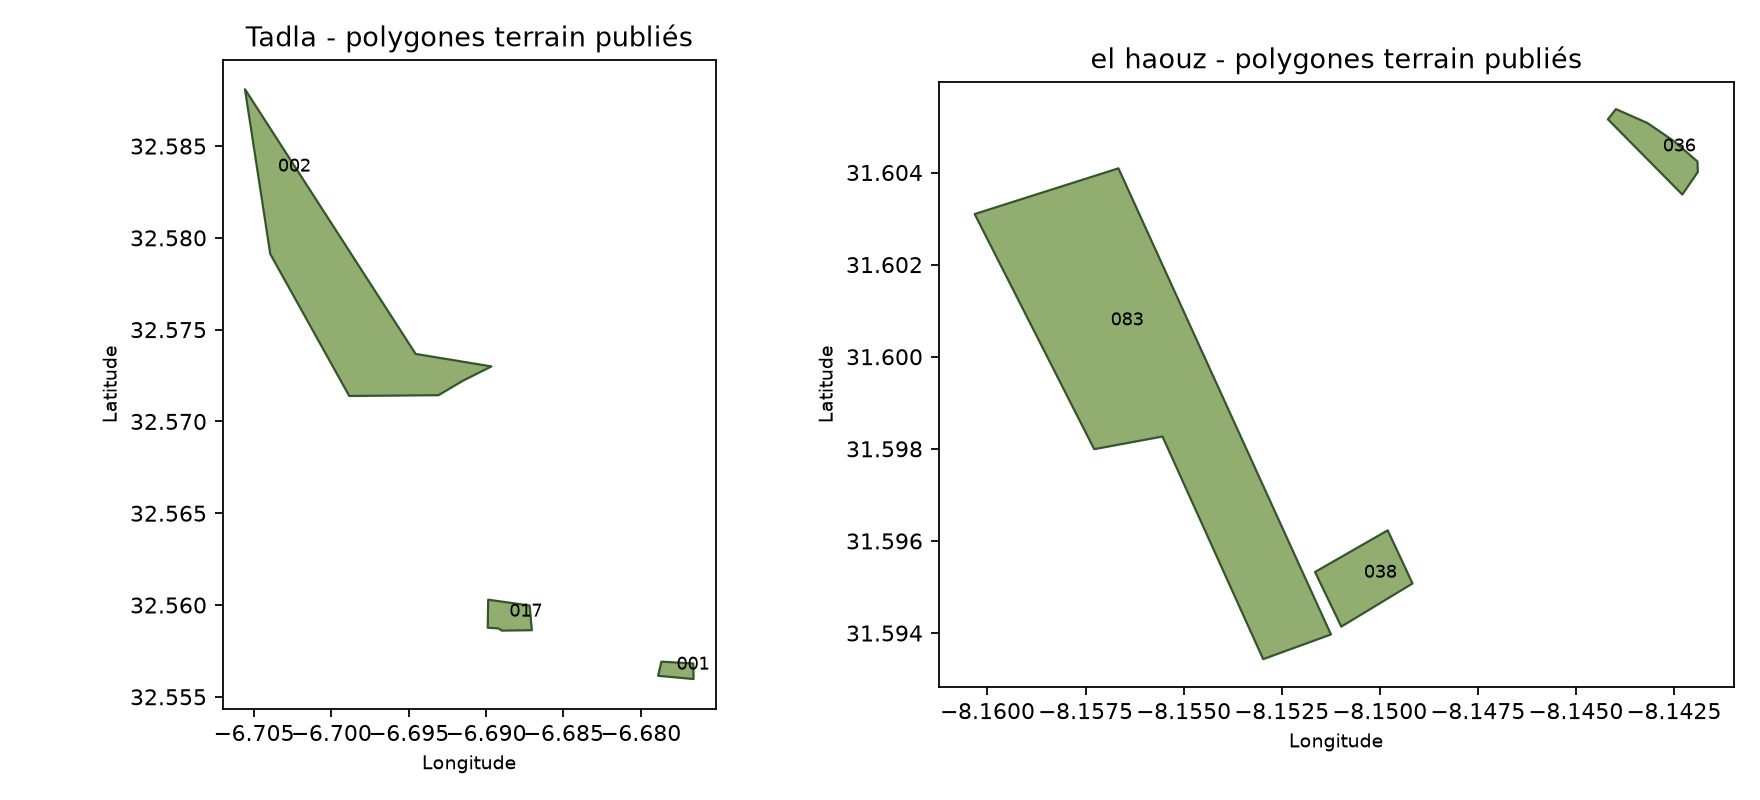

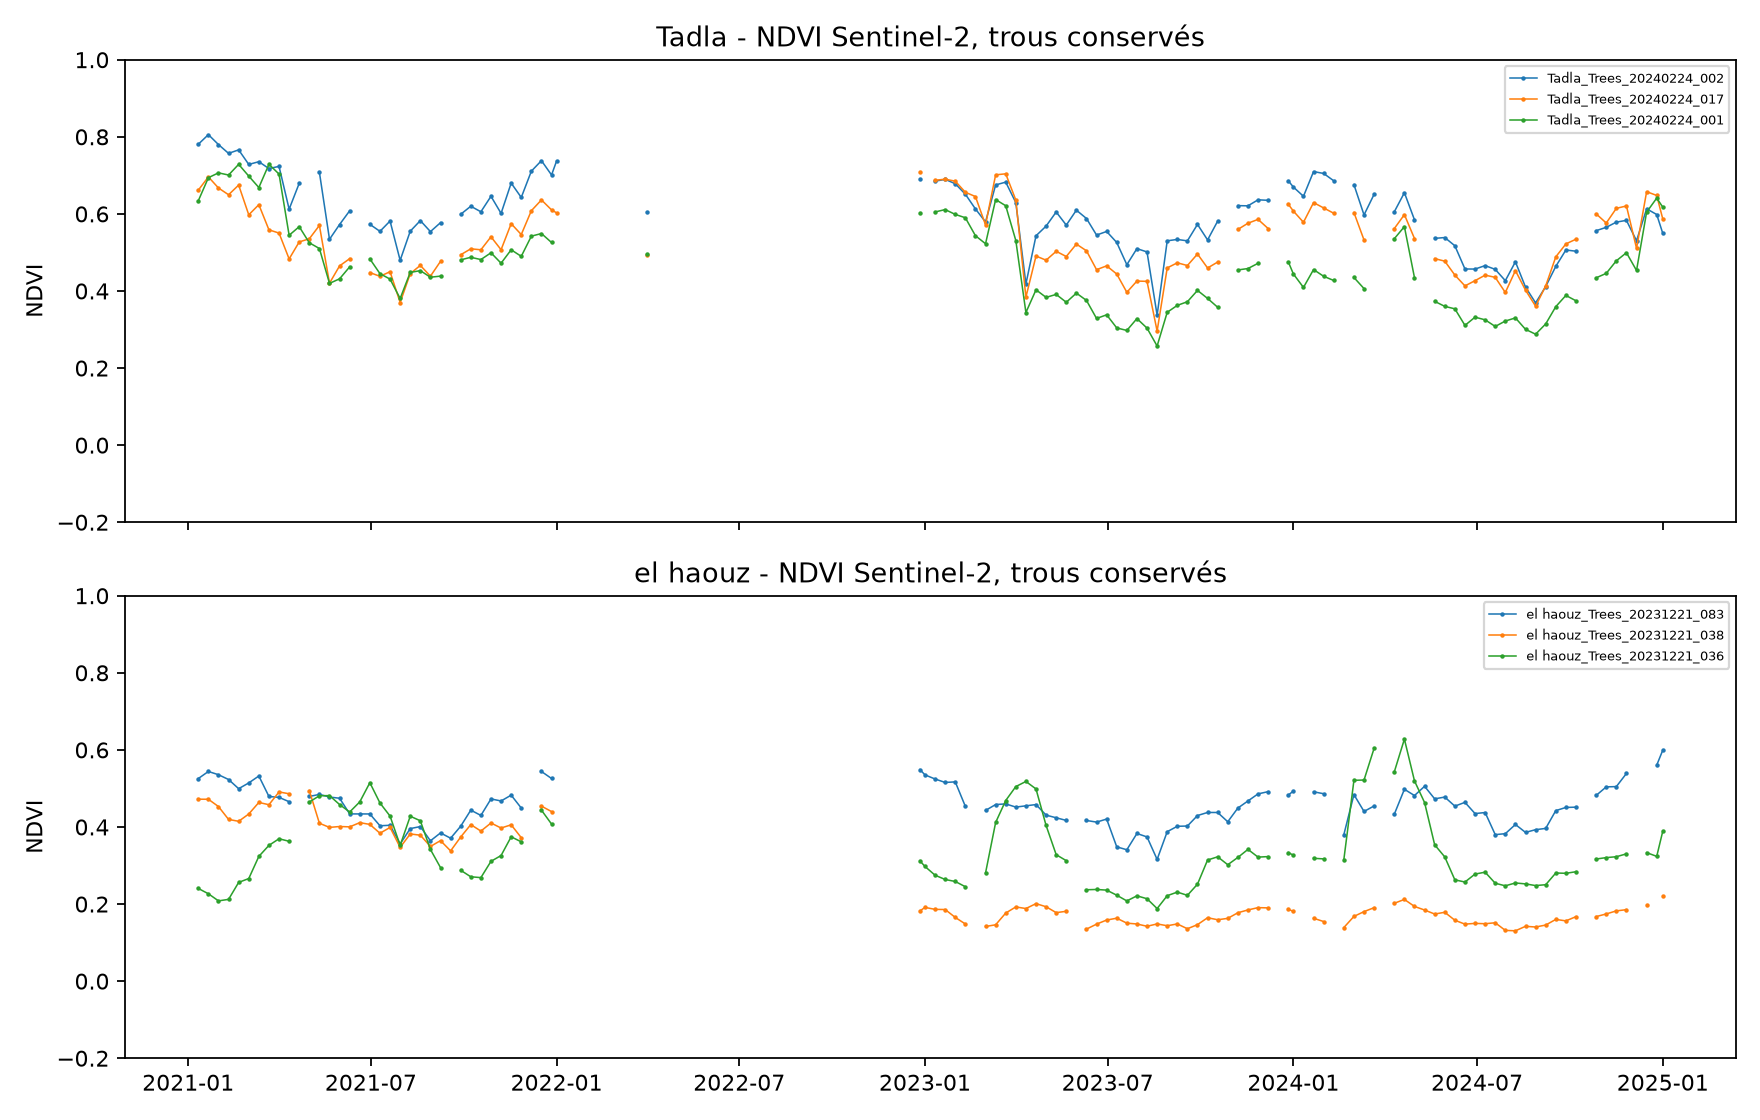

In [12]:
status=json.loads((ROOT/'outputs/pilot/import_status.json').read_text(encoding='utf-8'))
display(status)
display(pd.read_csv(ROOT/'outputs/pilot/coverage.csv'))
series=pd.read_csv(ROOT/'data/processed/pilot/sentinel2_10day_with_weather.csv')
display(series.groupby(['region','status']).size().rename('observations').reset_index())
display(Image(filename=str(ROOT/'outputs/pilot/pilot_map.png')))
display(Image(filename=str(ROOT/'outputs/pilot/ndvi_series.png')))


## Limites avant entraînement et évaluation
- La présence d'oliviers est documentée aux dates de visite ; l'historique de culture
  2021-2024 n'est pas entièrement confirmé. Il faut vérifier les changements de plantation.
- Les séries publiques 2024 et les découpes calculées ont des méthodes différentes :
  ne pas les empiler comme des observations indépendantes d'une même parcelle-date.
- Les six parcelles forment un **petit pilote**, pas une population représentative.
- Aucun événement de stress confirmé ni calendrier de surveillance exhaustive n'est
  fourni. Précision, rappel, F1, délai et faux positifs agronomiques restent non évaluables.
- Les identifiants d'exploitation et de bassin manquent. Une séparation par région
  peut être une expérience spatiale explicitement nommée, pas une preuve d'indépendance
  par exploitation ou de robustesse entre bassins.
- Un protocole d'apprentissage doit être fixé avant tout choix sur test. Ces imports
  ne déclenchent pas automatiquement le notebook historique de comparaison.


In [13]:
globals().update(_initial_paths)
print('Chemins du protocole initial restaurés ; données pilote conservées dans data/processed/pilot.')

Chemins du protocole initial restaurés ; données pilote conservées dans data/processed/pilot.


## Protocole expérimental
Deux évaluations : (1) campagnes futures sur les parcelles connues ; (2) bassin tenu
à l'écart, évalué uniquement après la validation temporelle sur les autres bassins.
Pour une série temporelle, une même parcelle peut être suivie entre campagnes ; ce n'est
pas un test d'indépendance spatiale. Le second protocole interdit le partage de bassin
et d'exploitation. Les fenêtres ne franchissent jamais les limites d'un split.
Les saisons et les échelles sont ajustées sur train seulement. Une régression harmonique
annuelle par parcelle (repli global pour parcelles inconnues) évite les z-scores mensuels
fragiles. Les valeurs manquantes ne sont pas interpolées ; une fenêtre discontinue
est rejetée. Test et validation ne servent jamais à ajuster cette normalisation.

Apprentissage sur observations confirmées normales lorsque disponibles ; sinon
apprentissage non supervisé possiblement contaminé, explicitement signalé.
Sans labels disponibles à la date de validation, optimisation par proximité d'un taux
d'alerte cible fixé à l'avance : ce critère n'est PAS une mesure de précision.
Le test est calculé après sélection de tous les choix, puis écrit dans un dossier verrouillé.

In [14]:
def read_source(name):
    paths=sorted((RAW/name).glob('*.csv'))
    return pd.concat([pd.read_csv(p) for p in paths],ignore_index=True) if paths else pd.DataFrame()
data=read_source('sentinel2'); weather=read_source('era5'); landsat=read_source('landsat')
FEATURES=['ndvi','ndre','ndwi','savi']
READY=not data.empty
if READY:
    required=['parcel_id','farm_id','basin','date','valid_fraction']+FEATURES
    assert set(required)<=set(data), f'Colonnes requises : {required}'
    data['date']=pd.to_datetime(data['date'],errors='raise')
    assert not data.duplicated(['parcel_id','date']).any(), 'Doublons à résoudre, pas à moyenner silencieusement'
    assert data.groupby('parcel_id')[['farm_id','basin']].nunique().max().max()==1
    assert data.groupby('farm_id').basin.nunique().max()==1
    display(data.dtypes.to_frame('type')); display(data.describe(include='all'))
    display(data.isna().sum().to_frame('manquants'))
    audit=data.groupby(['basin','parcel_id']).agg(first=('date','min'),last=('date','max'),n=('date','size'))
    audit.to_csv(OUT/'coverage.csv'); display(audit)
    assert data.valid_fraction.dropna().between(0,1).all()
    for f in ['ndvi','ndre','ndwi']: assert data[f].dropna().between(-1,1).all(), f
    data=data[data.valid_fraction.ge(CFG['min_valid_fraction'])].copy()
    if not weather.empty:
        weather['date']=pd.to_datetime(weather.date)
        assert not weather.duplicated(['parcel_id','date']).any()
        data=data.merge(weather[['parcel_id','date','temperature_c','precipitation_mm']],on=['parcel_id','date'],how='left',validate='one_to_one')
    data=data.sort_values(['parcel_id','date']).reset_index(drop=True)
    data['split']=np.select([data.date.lt(CFG['train_end']),data.date.lt(CFG['val_end'])],['train','val'],default='test')
    data=data[data.date.ge(CFG['start']) & data.date.lt(CFG['end'])].copy()
    if CFG['heldout_basin']:
        data.loc[data.basin.eq(CFG['heldout_basin']),'split']='excluded'
        data.loc[data.basin.eq(CFG['heldout_basin']) & data.date.ge(CFG['val_end']),'split']='spatial_test'
    if 'label' not in data: data['label']=np.nan
    assert data.label.dropna().isin([0,1]).all()
    if 'label_available_at' in data:
        available=pd.to_datetime(data.label_available_at)
        data.loc[data.split.eq('train') & available.ge(CFG['train_end']),'label']=np.nan
        data.loc[data.split.eq('val') & available.ge(CFG['val_end']),'label']=np.nan
    else:
        data['label']=np.nan
        print('Labels sans date de disponibilité ignorés pour éviter une fuite.')
    data.to_csv(PROCESSED/'series.csv',index=False)
    data[['parcel_id','farm_id','basin','date','split']].to_csv(OUT/'splits.csv',index=False)
else:
    print('Entraînement du protocole initial non lancé : entrée avec groupes exploitation/bassin absente. Les séries importées sur les oliveraies documentées sont décrites dans le bloc précédent et dans data/processed/pilot.')
display(pd.DataFrame({'source':['Sentinel-2','ERA5','Landsat'],'rows':[len(data),len(weather),len(landsat)]}))

Entraînement du protocole initial non lancé : entrée avec groupes exploitation/bassin absente. Les séries importées sur les oliveraies documentées sont décrites dans le bloc précédent et dans data/processed/pilot.


,source,rows
0,Sentinel-2,0
1,ERA5,0
2,Landsat,0


## Préparation : saisonnalité et fenêtres causales
Le z-score mesure le déficit de NDVI par rapport au cycle attendu. Les autres modèles
reçoivent les résidus saisonniers standardisés ; les ablations comparent NDVI seul,
quatre indices, puis indices + météo. Aucun remplissage depuis le futur.
Le schéma CSV accepte `label` (0/1, vide si inconnu) et `label_available_at` ; un zéro
doit être une absence de stress vérifiée, jamais une absence d'annotation.

In [15]:
def harmonic(dates):
    t=pd.DatetimeIndex(dates).dayofyear.to_numpy()/365.25*2*np.pi
    return np.column_stack([np.ones(len(t)),np.sin(t),np.cos(t),np.sin(2*t),np.cos(2*t)])
def season_fit(df, features):
    candidates=df[df.split.eq('train') & ~df.label.eq(1)].dropna(subset=features)
    confirmed=candidates[candidates.label.eq(0)]
    normal=confirmed if len(confirmed)>=20 else candidates
    if len(normal)<20: raise ValueError('Au moins 20 observations train valides requises')
    models={'global':Ridge(alpha=1).fit(harmonic(normal.date),normal[features])}
    for pid,g in normal.groupby('parcel_id'):
        if len(g)>=20 and (g.date.max()-g.date.min()).days>=365:
            models[pid]=Ridge(alpha=1).fit(harmonic(g.date),g[features])
    def residual(frame):
        r=np.full((len(frame),len(features)),np.nan)
        for pid,indices in frame.groupby('parcel_id').indices.items():
            g=frame.iloc[indices]
            expected=np.asarray(models.get(pid,models['global']).predict(harmonic(g.date))).reshape(len(g),len(features))
            r[indices]=g[features].to_numpy()-expected
        return r
    r=residual(df)
    train=df.index.isin(normal.index) & np.isfinite(r).all(axis=1)
    scaler=StandardScaler().fit(r[train])
    return scaler.transform(r),models,scaler
def windows(df,residual,length):
    x=[]; indices=[]
    # groupe par split : aucune fenêtre partagée entre train, validation et test
    for _,g in df.groupby(['parcel_id','split'],sort=False):
        ix=g.index.to_numpy()
        for end in range(length-1,len(ix)):
            selected=ix[end-length+1:end+1]
            dates=df.loc[selected,'date']
            if dates.diff().dropna().dt.days.gt(CFG['max_gap_days']).any(): continue
            if not np.isfinite(residual[selected]).all(): continue
            x.append(residual[selected].ravel()); indices.append(ix[end])
    if not x: raise ValueError('Aucune fenêtre valide : vérifier dates, couverture et longueur')
    return np.array(x,dtype=np.float32),np.array(indices)

## Modèle 1 — z-score NDVI
Baseline statistique transparente : score = opposé du dernier résidu NDVI standardisé.
Une baisse inhabituelle donne un score élevé. Le seuil est choisi en validation.
Les hausses inhabituelles ne sont pas ciblées par cette baseline de déficit.
## Modèle 2 — Isolation Forest
Modèle non supervisé multivarié : isolement des fenêtres atypiques. Recherche sur
`n_estimators`, `max_samples` et `contamination` sans consulter le test.
## Modèle 3 — One-Class SVM
Frontière de normalité RBF ; recherche sur `gamma` et `nu`. Coût quadratique potentiel,
limitation déterministe de l'apprentissage à 5 000 fenêtres pour les deux modèles ML.
## Modèle 4 — autoencoder
Reconstruction d'une fenêtre aplatie, architecture dense, perte MSE, AdamW,
recherche sur dimension latente, learning rate, poids de régularisation et fenêtre.
Checkpoint choisi sur erreur de reconstruction des données de validation normales
connues (ou non étiquetées), jamais sur test. Ce choix suppose la majorité normale.

In [16]:
class Autoencoder(nn.Module):
    def __init__(self, size, latent):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(size,32),nn.ReLU(),nn.Linear(32,latent),nn.ReLU(),nn.Linear(latent,32),nn.ReLU(),nn.Linear(32,size))
    def forward(self,x): return self.net(x)
def fit_method(name,train,val,params):
    rng=np.random.default_rng(SEED)
    sample=train[rng.choice(len(train),min(5000,len(train)),replace=False)]
    if name=='zscore': return None,[]
    if name=='isolation': return IsolationForest(random_state=SEED,n_jobs=1,**params).fit(sample),[]
    if name=='svm': return OneClassSVM(kernel='rbf',**params).fit(sample),[]
    torch.manual_seed(SEED)
    model=Autoencoder(train.shape[1],params['latent'])
    optimizer=torch.optim.AdamW(model.parameters(),lr=params['lr'],weight_decay=params['weight_decay'])
    a=torch.tensor(train); b=torch.tensor(val)
    best=float('inf'); checkpoint=None; history=[]; stale=0
    for epoch in range(100):
        model.train(); losses=[]
        for batch in torch.randperm(len(a)).split(128):
            optimizer.zero_grad(); loss=((model(a[batch])-a[batch])**2).mean()
            loss.backward(); optimizer.step(); losses.append(loss.item())
        model.eval()
        with torch.no_grad(): v=((model(b)-b)**2).mean().item()
        history.append({'epoch':epoch,'train':float(np.mean(losses)),'validation':v})
        if v<best-1e-6: best=v; checkpoint=copy.deepcopy(model.state_dict()); stale=0
        else: stale+=1
        if stale>=10: break
    model.load_state_dict(checkpoint)
    return model,history
def score(name,model,x,n_features):
    if name=='zscore': return -x[:,-n_features]
    if name in ['isolation','svm']: return -model.score_samples(x)
    model.eval()
    with torch.no_grad(): return ((model(torch.tensor(x))-torch.tensor(x))**2).mean(dim=1).numpy()
def metrics(y,s,threshold):
    known=np.isfinite(y); y=y[known].astype(int); s=s[known]
    if not len(y): return dict(n_labelled=0,precision=None,recall=None,f1=None,ap=None,auc=None)
    pred=s>threshold
    tp=int(((y==1)&pred).sum()); fp=int(((y==0)&pred).sum()); fn=int(((y==1)&~pred).sum())
    precision=tp/(tp+fp) if tp+fp else None
    recall=tp/(tp+fn) if tp+fn else None
    f1=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else None
    return dict(n_labelled=len(y),n_positive=int(y.sum()),tp=tp,fp=fp,fn=fn,
                precision=precision,recall=recall,f1=f1,
                ap=float(average_precision_score(y,s)) if len(set(y))==2 else None,
                auc=float(roc_auc_score(y,s)) if len(set(y))==2 else None,
                confusion=confusion_matrix(y,pred,labels=[0,1]).tolist())
def threshold_validation(scores,labels):
    thresholds=np.unique(np.quantile(scores,np.linspace(.80,.995,40)))
    labelled=np.isfinite(labels)
    supervised=labelled.sum()>0 and len(np.unique(labels[labelled]))==2
    def objective(t):
        if supervised: return metrics(labels,scores,t)['f1'] or 0.
        return -abs(float((scores>t).mean())-CFG['target_alert_rate'])
    selected=max(thresholds,key=objective)
    return float(selected),float(objective(selected)), 'F1 validation' if supervised else 'taux alerte cible (pas une performance)'

## Optimisation et ablations
Budget TPE fixé à 12 essais par méthode et ablation ; 3 longueurs de fenêtre (1,3,6).
La comparaison finale utilise l'intersection des observations de test accessibles à
tous les gagnants, pour que les métriques portent sur les mêmes exemples.
L'agrégation 10 jours, le filtre nuage et la qualité sont fixés avant extraction ; les
variantes 5/15 jours demandent des extractions et expériences séparées, sans retoucher
les choix après le test. Pas de lissage par défaut pour préserver les ruptures.

In [17]:
winners=[]; trials_log=[]
if READY and RUN_EXPERIMENT:
    data=data.reset_index(drop=True)
    assert {'train','val','test'}<=set(data.split), 'Splits temporels incomplets'
    ablations={'ndvi':['ndvi'],'indices':FEATURES}
    if {'temperature_c','precipitation_mm'}<=set(data):
        ablations['meteo']=FEATURES+['temperature_c','precipitation_mm']
    for ablation,features in ablations.items():
        residual,season,scaler=season_fit(data,features)
        for name in ['zscore','isolation','svm','autoencoder']:
            if name=='zscore' and ablation!='ndvi': continue
            best_holder={}
            def objective(trial):
                length=trial.suggest_categorical('length',[1,3,6])
                x,ix=windows(data,residual,length)
                subset=data.loc[ix]; tr=subset.split.eq('train').to_numpy(); va=subset.split.eq('val').to_numpy()
                tr &= ~subset.label.eq(1).to_numpy()
                normal_val=va & ~subset.label.eq(1).to_numpy()
                confirmed_train=tr & subset.label.eq(0).to_numpy()
                confirmed_val=va & subset.label.eq(0).to_numpy()
                if confirmed_train.sum()>=20: tr=confirmed_train
                if confirmed_val.sum()>=5: normal_val=confirmed_val
                if tr.sum()<20 or normal_val.sum()<5: raise optuna.TrialPruned('Couverture insuffisante')
                params={}
                if name=='isolation': params=dict(n_estimators=trial.suggest_categorical('n_estimators',[100,250]),max_samples=trial.suggest_categorical('max_samples',[.5,1.]),contamination=trial.suggest_float('contamination',.01,.1))
                if name=='svm': params=dict(gamma=trial.suggest_float('gamma',1e-4,1.,log=True),nu=trial.suggest_float('nu',.01,.2))
                if name=='autoencoder': params=dict(latent=trial.suggest_categorical('latent',[2,4,8]),lr=trial.suggest_float('lr',1e-4,1e-2,log=True),weight_decay=trial.suggest_float('weight_decay',1e-6,1e-2,log=True))
                model,history=fit_method(name,x[tr],x[normal_val],params)
                scores=score(name,model,x[va],len(features))
                threshold,value,criterion=threshold_validation(scores,subset.loc[va,'label'].to_numpy(float))
                if not best_holder or value>best_holder['value']:
                    best_holder.update(value=value,name=name,ablation=ablation,features=features,params=params,length=length,threshold=threshold,criterion=criterion,model=model,history=history,season=season,scaler=scaler,x=x,ix=ix)
                return value
            study=optuna.create_study(direction='maximize',sampler=optuna.samplers.TPESampler(seed=SEED))
            study.optimize(objective,n_trials=CFG['trials'])
            study.trials_dataframe().to_csv(OUT/f'trials_{ablation}_{name}.csv',index=False)
            if best_holder: winners.append(best_holder)
    print('Modèles sélectionnés uniquement sur validation :',len(winners))
else: print('Optimisation non exécutée : séries réelles absentes.')

Optimisation non exécutée : séries réelles absentes.


## Comparaison finale et indicateurs
Précision/rappel/F1 ponctuels sur labels confirmés ; AP et AUC seulement si les deux
classes existent. Les valeurs non évaluables restent nulles. Taux d'alertes et effectifs
sont toujours affichés mais ne prouvent pas la fiabilité.

Les métriques événementielles nécessitent `events.csv` (événements confirmés) et
`surveillance.csv` (intervalles de surveillance exhaustive, dates de fin inclusives).
Les alertes consécutives sont regroupées en épisodes, puis appariées une à une aux
événements avec la tolérance prédéfinie. Une alerte hors surveillance n'est pas un faux
positif connu. Délai = jours après début, ramené à zéro pour une alerte anticipée.
Stabilité interannuelle : dispersion du taux d'alertes par campagne, descriptive et
potentiellement affectée par des changements réels de stress ou de couverture.

In [18]:
def event_metrics(pred):
    events=pd.read_csv(morocco/'events.csv'); coverage=pd.read_csv(morocco/'surveillance.csv')
    if coverage.empty: return {'event_precision':None,'event_recall':None,'event_f1':None,'mean_delay_days':None,'fp_per_parcel':None,'reason':'Surveillance exhaustive absente'}
    for c in ['start','end']: coverage[c]=pd.to_datetime(coverage[c])
    for c in ['onset','end','available_at']: events[c]=pd.to_datetime(events[c])
    assert not events.event_id.duplicated().any()
    lo,hi=pred.date.min(),pred.date.max()
    coverage=coverage[(coverage.end>=lo)&(coverage.start<=hi)].copy()
    coverage['start']=coverage.start.clip(lower=lo)
    coverage['end']=coverage.end.clip(upper=hi)
    episodes=[]; eligible=[]; parcels=set()
    for pid,group in pred.groupby('parcel_id'):
        cov=coverage[coverage.parcel_id.eq(pid)]
        if cov.empty: continue
        parcels.add(pid)
        monitored=group.date.map(lambda d: ((cov.start<=d)&(cov.end>=d)).any())
        dates=group.loc[monitored & group.alert,'date'].sort_values()
        last=None
        for d in dates:
            if last is None or (d-last).days>CFG['max_gap_days']: episodes.append((pid,d))
            last=d
        for row in events[events.parcel_id.eq(pid) & events.confirmed.eq(1)].itertuples():
            tol=pd.Timedelta(days=CFG['event_tolerance_days'])
            if ((cov.start<=row.onset-tol)&(cov.end>=row.end+tol)).any(): eligible.append(row)
    used=set(); delays=[]
    # Ordre chronologique et une seule correspondance par épisode et événement.
    for pid,d in sorted(episodes,key=lambda e:e[1]):
        candidates=[e for e in eligible if e.parcel_id==pid and e.event_id not in used and e.onset-pd.Timedelta(days=CFG['event_tolerance_days'])<=d<=e.end+pd.Timedelta(days=CFG['event_tolerance_days'])]
        if candidates:
            e=min(candidates,key=lambda e:abs((d-e.onset).days)); used.add(e.event_id); delays.append(max(0,(d-e.onset).days))
    tp=len(used); fp=len(episodes)-tp; fn=len(eligible)-tp
    return dict(event_precision=tp/len(episodes) if episodes else None,event_recall=tp/len(eligible) if eligible else None,event_f1=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else None,mean_delay_days=float(np.mean(delays)) if delays else None,fp_per_parcel=fp/len(parcels) if parcels else None,n_events=len(eligible),n_episodes=len(episodes),n_monitored_parcels=len(parcels))
results=[]
if winners:
    # Verrouillage avant le premier calcul des scores de test.
    lock=OUT/'locked_protocol.json'
    if lock.exists(): raise RuntimeError('Expérience déjà verrouillée : conserver ce dossier et choisir un nouveau dossier outputs pour une nouvelle expérience.')
    choices=[{k:w[k] for k in ['name','ablation','params','length','threshold','criterion']} for w in winners]
    lock.write_text(json.dumps({'config':CFG,'choices':choices,'seed':SEED},indent=2))
    for split in ['test','spatial_test']:
        sets=[set(w['ix'][data.loc[w['ix'],'split'].eq(split)]) for w in winners]
        common=sorted(set.intersection(*sets))
        if not common: continue
        for w in winners:
            positions=np.array([np.flatnonzero(w['ix']==i)[0] for i in common])
            start=time.perf_counter(); s=score(w['name'],w['model'],w['x'][positions],len(w['features'])); seconds=time.perf_counter()-start
            pred=data.loc[common,['parcel_id','farm_id','basin','date','label']].copy()
            pred['score']=s; pred['alert']=s>w['threshold']
            tag=w['ablation']+'_'+w['name']
            pred.to_csv(OUT/f'predictions_{split}_{tag}.csv',index=False)
            row=dict(split=split,model=w['name'],ablation=w['ablation'],n=len(s),alert_rate=float(pred.alert.mean()),inference_seconds=seconds,**metrics(pred.label.to_numpy(float),s,w['threshold']),**event_metrics(pred))
            annual=pred.assign(year=pred.date.dt.year).groupby('year').alert.agg(['mean','count'])
            annual.to_csv(OUT/f'annual_{split}_{tag}.csv')
            row['annual_alert_rate_std']=float(annual['mean'].std()) if len(annual)>1 else None
            results.append(row)
    display(pd.DataFrame(results))
    pd.DataFrame(results).to_csv(OUT/'comparison.csv',index=False)
else: print('Comparaison indisponible : aucun entraînement réel effectué.')

Comparaison indisponible : aucun entraînement réel effectué.


## Historique Landsat indépendant
Le capteur est conservé séparément. Cette courbe historique aide à inspecter la
saisonnalité à 30 m, sans supposer l'équivalence radiométrique à Sentinel-2.
La fusion nécessiterait une calibration sur dates communes et parcelles compatibles.

In [19]:
if not landsat.empty:
    landsat['date']=pd.to_datetime(landsat.date)
    assert not landsat.duplicated(['parcel_id','date']).any()
    history=landsat[landsat.valid_fraction.ge(CFG['min_valid_fraction'])].copy()
    history['month']=history.date.dt.month
    baseline=history[history.date.lt(CFG['train_end'])].groupby(['parcel_id','month']).ndvi.agg(['mean','std','count'])
    baseline.to_csv(OUT/'landsat_historical_baseline.csv'); display(baseline)
else: print('Historique Landsat non extrait : baseline non calculée.')

Historique Landsat non extrait : baseline non calculée.


## Sauvegarde et vérifications
Export des transformations saisonnières, modèles, seuils, configuration, splits,
prédictions, courbes et versions. Pas d'ONNX ici : export optionnel, non nécessaire
à cette phase expérimentale. Le chronométrage mesure le scoring en mémoire sur les
fenêtres de test communes, hors téléchargement et prétraitement.

In [20]:
for w in winners:
    tag=w['ablation']+'_'+w['name']
    bundle={k:w[k] for k in ['name','features','params','length','threshold','season','scaler']}
    if w['name']=='autoencoder':
        torch.save(w['model'].state_dict(),OUT/f'{tag}.pt')
        pd.DataFrame(w['history']).to_csv(OUT/f'{tag}_learning.csv',index=False)
        pd.DataFrame(w['history']).set_index('epoch').plot(); plt.title(tag); plt.ylabel('MSE'); plt.show()
    else: bundle['model']=w['model']
    joblib.dump(bundle,OUT/f'{tag}.joblib')
versions={d.metadata['Name']:d.version for d in importlib.metadata.distributions() if d.metadata['Name']}
(META/'environment.json').write_text(json.dumps({'python':sys.version,'platform':platform.platform(),'packages':versions,'seed':SEED},indent=2))
(OUT/'status.json').write_text(json.dumps({'real_data_available':bool(READY or local_rows),'training_series_available':READY,'local_acquisitions':len(local_rows),'trained_models':len(winners),'metrics_available':bool(results),'blockers':[] if READY else ['Parcelles oléicoles et groupes non confirmés','Séries multi-temporelles insuffisantes','Vérité terrain et surveillance à constituer']},indent=2,ensure_ascii=False))
# Tests ciblés sur petites valeurs artificielles : pas des résultats expérimentaux.
assert metrics(np.array([1.,0.,np.nan]),np.array([2.,0.,9.]),1)['f1']==1
assert metrics(np.array([np.nan]),np.array([2.]),1)['precision'] is None
toy=pd.DataFrame({'parcel_id':['a']*6,'split':['train']*3+['test']*3,'date':pd.date_range('2020-01-01',periods=6,freq='10D')})
wx,wi=windows(toy,np.arange(6,dtype=float).reshape(-1,1),3)
assert wi.tolist()==[2,5] and wx.tolist()==[[0.,1.,2.],[3.,4.,5.]]
toy.loc[2,'date']=pd.Timestamp('2020-03-01')
_,wi=windows(toy,np.ones((6,1)),3); assert wi.tolist()==[5]
if READY:
    assert data[data.split.eq('train')].date.max()<pd.Timestamp(CFG['train_end'])
    assert data[data.split.eq('val')].date.max()<pd.Timestamp(CFG['val_end'])
    if CFG['heldout_basin']:
        a=set(data[data.split.isin(['train','val'])].farm_id)
        b=set(data[data.split.eq('spatial_test')].farm_id)
        assert not a&b
print('Tests de métriques, frontières temporelles et discontinuités : OK')

Tests de métriques, frontières temporelles et discontinuités : OK

## Interprétation, limites et prochaines étapes
Aucun meilleur modèle ne peut être annoncé sans séries extraites et vérité terrain.
L'absence de labels permet seulement de comparer taux d'alerte, stabilité et coûts,
pas de conclure à la précision de détection. Les saisons atypiques, sols nus, cultures
intercalaires, taille des parcelles, pluies et irrigation peuvent expliquer des alertes.
La météo peut contextualiser le signal mais ne révèle pas la cause du stress.

Avant une étude opérationnelle : constituer les polygones et visites marocaines,
fixer campagnes et bassin exclus, vérifier couverture/pixels mixtes, examiner les
labels datés, exécuter l'extraction puis Run All. Une baseline fiable demande plusieurs
cycles annuels. Préenregistrer un protocole distinct pour tester agrégation 5/15 jours,
persistance et lissage causal. Conserver ce test intact pour toute comparaison ultérieure.